[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_KillChainAttack_Brugmann2026.ipynb)

# QNN kill-chain attack (side channel -> adversarial example -> crosstalk): Brügmann et al. 2026 step by step

**Paper.** C. Brügmann, D. Herr, D. Ohl de Mello, P. Debus, M. Wendlinger, K. Tscharke, J. Ulmanis, A. Erhard, A. Schmidt, F. Petsch,
*An End-to-End Multi-Stage Kill-Chain Attack on Quantum Neural Networks: Demonstration on Trapped-Ion Hardware*,
arXiv:2607.03337 (July 2026). <https://arxiv.org/abs/2607.03337>. Project: BSI QML-ESA.

**What this notebook does.** The paper attacks a small quantum neural network (QNN, a 4-qubit data-re-uploading classifier) in
three chained stages and runs the last stage on the AQT *Ibex* trapped-ion computer:

1. **Reconnaissance** - from a (simulated) power trace of the control electronics the attacker finds out the circuit structure
   (number of qubits, layers, CNOT pattern) by matching against 24 benchmark circuits.
2. **Adversarial examples** - white-box projected gradient descent (PGD) finds the smallest l-infinity perturbation `eps` that flips the QNN's decision;
   a second, *masked* PGD only perturbs the features that are encoded in `RY` gates, because on trapped ions only `RY` pulses leak (crosstalk) onto neighbouring ions.
3. **Physical attack** - the attacker runs `RY` rotations on the neighbouring ions of the victim at the right moments; crosstalk makes the victim's
   effective `RY` angles shift, which approximates the adversarial example.

**What we can and cannot do here.** We have no trapped-ion computer and no pulse-level power traces. Stages 1 and 2 of the paper are
simulations in the paper too (the power trace is *simulated* with the formulas given in the paper, the PGD runs on a state-vector
simulator), so we reproduce them completely. Stage 3 is the only hardware experiment: we **emulate** it with the paper's own linear crosstalk
model (`theta_induced = f * gamma`) plus a generic noisy trapped-ion noise model in Qiskit Aer. The hardware numbers of the paper (Tables VIII, IX, XIV, XVI, XVII,
superconducting appendix A) are therefore marked **cannot be checked**; the emulated numbers are reported next to them but are *not* a replication of the hardware experiment.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. Everything is downloaded or generated inside the notebook. `FAST_MODE = True` is a
class demo (about 10 minutes); `FAST_MODE = False` follows the paper's sample sizes (1000 training images, 50 emulated hardware samples) and takes longer (see the config cell).
**What you get at the end:** the victim QNN (96 parameters), the recovered circuit structure, Table VI/VII-style histograms, the effect of crosstalk-style input
shifts, a comparison with a classical network of similar size, and a side-by-side table of the paper's numbers and ours with a verdict per claim.

**Data.** The paper uses the public *PlusMinus* dataset of Wendlinger et al. (2024) distributed through PennyLane Datasets (1000 train / 200 test images, 16x16, four classes).
No Hugging Face token is needed (the dataset is not gated).

## The paper in one page

* **Task.** Classify 16x16 grey-scale images of four symbols `-`, `+`, `|-`, `-|` (classes 0..3).
* **Victim QNN.** PCA to the top 16 components; 4 qubits; `L = 4` `StronglyEntanglingLayers`; each of the 48 = 4 layers x 4 qubits x 3 slots rotation angles is `w * x + theta` with a trainable weight `w` and bias `theta`
  (the 16 PCA features are re-uploaded three times, so `x` has 48 entries, assigned in the order `(RZ, RY, RZ)` of every general rotation); CNOT ring with range `r = (layer mod (n-1)) + 1`.
  Output: `<Z>` on the four qubits -> `argmax` = class. Trainable parameters: 4 x 4 x 3 x 2 = **96**. Reported accuracy: **0.885 train / 0.875 test** (1000 / 200 images).
* **Stage 1 (power trace).** Each native gate (`RZ` virtual = no pulse, `R(theta, phi)` = one 10 us pulse of amplitude `alpha_i * theta / pi`, `RXX(theta)` = one 200 us pulse of amplitude `beta_ij * theta / pi`, each followed by 2 us idle)
  gives a step function. A timing filter keeps benchmark circuits with the same duration, then the L2 distance picks the best match. Reported: three candidates left, distances **9.84** (correct circuit) vs **119.14** and **132.14**.
* **Stage 2 (PGD).** `T = 100` iterations, step `alpha = 0.01`, `eps` from 0.1 to 1.0 in steps of 0.1, l-infinity; the smallest successful `eps` is recorded (Table VI). **840/1000** training samples are broken, accuracy collapses to **1.07 %**.
* **Stage 3 (masked PGD + crosstalk).** Only features in `RY` slots may change (Table VII: **338** of the 885 correctly classified samples are breakable). The needed angle shift `d_theta = w * (x_adv - x)` is produced by `RY(gamma)` on both neighbouring ions with `gamma = d_theta / (2 f)`, `f = 0.01` (measured crosstalk factor, Table IV),
  saturated at `pi` and split into several `RY(+-pi)` pulses. 50 samples were run on hardware: accuracy clean/adversarial/crosstalk = **0.64 / 0.56 / 0.68** (Table VIII) and mean absolute errors between expectation vectors (Table IX).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | PlusMinus, 1000 train / 200 test, 16x16, 4 classes | the same public dataset (PennyLane Datasets); no substitution |
| PCA | top 16 components, scaling not stated | PCA(16) fitted on the training split only, **no extra scaling** (`# CHOICE`) |
| Circuit | 4 qubits, 4 StronglyEntanglingLayers, w*x+theta, 96 parameters | identical; verified against `qml.StronglyEntanglingLayers` |
| Range `r` | text says `r = l mod M` (0 -> 1); PennyLane default is `(l mod (M-1)) + 1` | PennyLane default (`# CHOICE`, the paper says it used the default of the template) |
| Output / loss | `<Z>` of each qubit -> argmax; loss not stated | softmax over `<Z>` + cross-entropy (as in Wendlinger et al. 2024) |
| Training | optimiser, lr, epochs, batch, init not stated for the 4-qubit model | Adam, lr 0.01, batch 50, 20 epochs, `w ~ N(0, 0.3)`, `theta ~ U(0, 2 pi)` (`# CHOICE`; picked from a handful of settings because it gives a victim with about the paper's accuracy, see section 4) |
| Power trace | formulas of Sec. IV-D | implemented as written; transpile to `rz, r, rxx` with `optimization_level=0`; angles of the victim wrapped to `[0, 2 pi)`; qubits `0..n-1` (`# CHOICE`) |
| Benchmarks | 24 circuits (4/8 qubits, 2/4/6/8 layers, r = 1, 2, default), random angles | same 24; the paper's index "7, 8, 9" is not reproducible from the text, we label by `(qubits, layers, r)` |
| PGD | T=100, alpha=0.01, eps 0.1..1.0, l-inf | same; PGD stops at the first iteration whose prediction differs from the unperturbed one (`# CHOICE`); loss uses the true label |
| Masked PGD | mask on `RY` slots of the 48-vector | same |
| Crosstalk | uniform factor f = 0.01 assumed by the attacker | the attacker uses f = 0.01; the emulated "device" uses the per-ion couplings of Table IV (0.007 at the chain ends, 0.010 inside, symmetric) (`# CHOICE`) |
| Hardware | AQT Ibex, trapped ions | **not available**: Aer density-matrix emulation with generic trapped-ion noise (1q depolarising 0.1 %, 2q depolarising 2 %, read-out 1 %, 2000 shots) (`# CHOICE`, not calibrated to the paper) |
| Superconducting appendix | IQM Emerald, Fake7QPulseV1 | **cannot be checked** (hardware / pulse backend removed from Qiskit 2.x) |
| Seeds | not stated | `SEED = 42` everywhere |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib.
# On a machine where everything is already importable nothing is reinstalled. A session restart may be required after the install.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
if IN_COLAB or not all(_have(m) for m in ["pennylane", "qiskit", "qiskit_aer", "h5py", "pylatexenc"]):
    !pip -q install "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc h5py requests aiohttp

In [2]:
# ---- configuration: every tunable constant lives here ---------------------------------------------------------
SEED = 42
FAST_MODE = False           # True: class demo (~10 min). False: paper-sized run (1000 attacked samples, 50 emulated hardware samples)
DATA_DIR = "qc050_data"     # downloaded data is cached here
IBM_TOKEN = ""              # unused: the paper's hardware (AQT Ibex trapped ions) is not accessible; kept for the convention

N_QUBITS, N_LAYERS = 4, 4   # victim QNN (paper Sec. IV-B)
N_PCA = 16                  # PCA components = input features
LR, EPOCHS, BATCH, W_INIT = 0.01, 20, 50, 0.3   # CHOICE: training budget and init scale of the encoding weights w (not stated for the 4-qubit model)
TRAIN_SEEDS = [SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2]   # extra seeds only for the accuracy mean +- std

PGD_T, PGD_ALPHA = 100, 0.01          # Table III
EPS_GRID = [round(0.1 * k, 1) for k in range(1, 11)]   # 0.1 ... 1.0

N_ATTACK_STAGE2 = 200 if FAST_MODE else 1000   # training samples attacked in stage 2 (paper: 1000)
N_ATTACK_STAGE3 = 300 if FAST_MODE else 1000   # correctly classified samples considered for masked PGD (paper: 885)
N_HW = 20 if FAST_MODE else 50                 # emulated "hardware" samples (paper: 50)
N_POWER_VICTIMS = 10 if FAST_MODE else 50      # victim samples for the power-trace identification statistics

SHOTS = 2000                          # AQT max shots per job (Appendix B)
NOISE = dict(p1=1e-3, p2=2e-2, ro=1e-2)   # CHOICE: generic trapped-ion noise, NOT calibrated to the paper
F_ASSUMED = 0.01                      # crosstalk factor assumed by the attacker (Table IV text)
ION_POS = [3, 5, 7, 9]                # physical ions of the victim qubits (Sec. IV-F2)
# couplings of the emulated device between a neighbour ion (first) and a victim ion (second); CHOICE from Table IV, pi/2 row
F_TRUE = {(2, 3): .007, (4, 3): .010, (4, 5): .010, (6, 5): .010, (6, 7): .010, (8, 7): .010, (8, 9): .010, (10, 9): .007}

In [3]:
import os, time, math, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import h5py, requests, io
import autograd.numpy as anp
from autograd import grad
import pennylane as qml
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
import qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
RNG = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
print("numpy", np.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("FAST_MODE =", FAST_MODE)

numpy 2.5.4 | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2
FAST_MODE = False


## 1. Data

The *PlusMinus* dataset (Wendlinger, Tscharke, Debus 2024) is hosted by PennyLane Datasets. We download the HDF5 file directly (with `requests`) and fall back to
`qml.data.load("other", name="plus-minus")`; the arrays are cached in `DATA_DIR`. Images are 16x16 grey values in [0, 1]; labels are 0 = `-`, 1 = `+`, 2 = `|-`, 3 = `-|`.
No gated dataset and no Hugging Face token is involved (if you ever swap in a gated Hugging Face dataset, put your own token in Colab *Secrets* as `HF_TOKEN`; never paste it into a notebook).

In [4]:
H5_URL = "https://datasets.cloud.pennylane.ai/datasets/h5/other/PlusMinus/PlusMinus_PlusMinus.h5"
CLASS_NAMES = ["-", "+", "|-", "-|"]

def load_plus_minus(data_dir=DATA_DIR):
    cache = os.path.join(data_dir, "plus_minus.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        return z["img_train"], z["labels_train"], z["img_test"], z["labels_test"]
    try:                                                   # 1) direct download of the public HDF5 file
        r = requests.get(H5_URL, timeout=120); r.raise_for_status()
        f = h5py.File(io.BytesIO(r.content), "r")
        arrs = [f[k][()] for k in ["img_train", "labels_train", "img_test", "labels_test"]]
    except Exception as e:                                 # 2) fallback: PennyLane's own loader
        print("direct download failed (", e, ") -> qml.data.load")
        ds = qml.data.load("other", name="plus-minus", folder_path=data_dir)[0]
        arrs = [np.asarray(getattr(ds, k)) for k in ["img_train", "labels_train", "img_test", "labels_test"]]
    np.savez_compressed(cache, img_train=arrs[0], labels_train=arrs[1], img_test=arrs[2], labels_test=arrs[3])
    return arrs

img_tr, y_tr, img_te, y_te = load_plus_minus()
y_tr, y_te = y_tr.astype(int), y_te.astype(int)
X_tr_pix = img_tr.reshape(len(img_tr), -1).astype(float)
X_te_pix = img_te.reshape(len(img_te), -1).astype(float)
print("train images", img_tr.shape, "test images", img_te.shape, "| pixel range", X_tr_pix.min(), X_tr_pix.max())

train images (1000, 16, 16) test images (200, 16, 16) | pixel range 0.0 1.0


## Dataset Exploration and Visualisation

We print the shape, the feature names and the label values/counts, show real images of every class, plot the real class distribution, and project the **real** observations to two dimensions with PCA
(fitted on the training split only), coloured by the ground-truth label. The model is angle-based (every feature enters a rotation angle), so we also show the same coordinates scaled to [0, pi] (display only: the QNN itself is trained on the raw PCA coordinates).

pixel features: 256 -> 4 classes; original label values: [0, 1, 2, 3]
feature names (first 4 / last 2): ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3'] ... ['pixel_15_14', 'pixel_15_15']
PCA feature names: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16']
train class counts: {'-': 250, '+': 250, '|-': 250, '-|': 250} | test class counts: {'-': 50, '+': 50, '|-': 50, '-|': 50}
PCA(16) explained variance: 0.969 | PCA feature range [-3.06, 3.59]


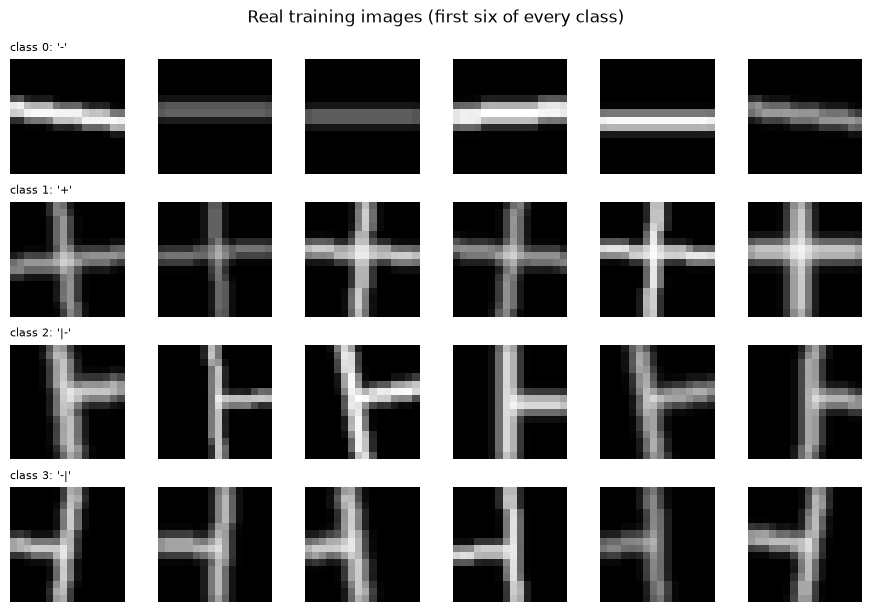

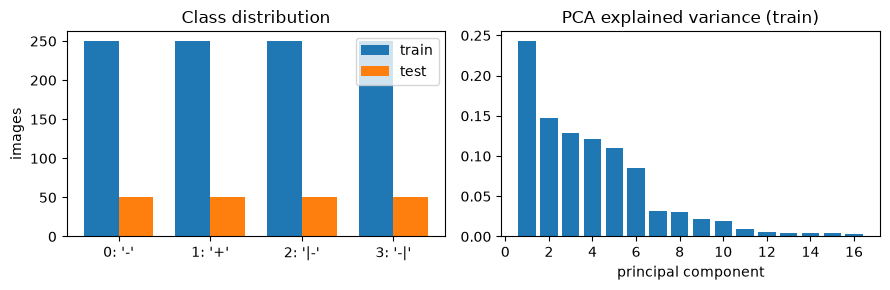

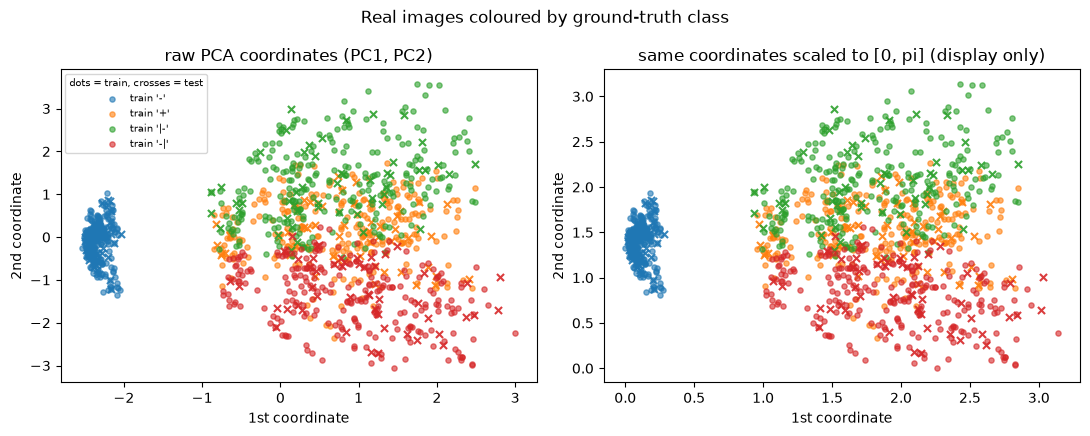

In [5]:
# PCA fitted on the training split only (paper: top-16 principal components)
pca = PCA(n_components=N_PCA, random_state=SEED).fit(X_tr_pix)
X_tr, X_te = pca.transform(X_tr_pix), pca.transform(X_te_pix)       # CHOICE: no extra scaling
print("pixel features:", X_tr_pix.shape[1], "->", f"{len(CLASS_NAMES)} classes; original label values:", [int(v) for v in sorted(set(y_tr))])
feature_names = [f"pixel_{r}_{c}" for r in range(16) for c in range(16)]
print("feature names (first 4 / last 2):", feature_names[:4], "...", feature_names[-2:])
print("PCA feature names:", [f"PC{i+1}" for i in range(N_PCA)])
print("train class counts:", dict(zip(CLASS_NAMES, np.bincount(y_tr).tolist())), "| test class counts:", dict(zip(CLASS_NAMES, np.bincount(y_te).tolist())))
print("PCA(16) explained variance: %.3f | PCA feature range [%.2f, %.2f]" % (pca.explained_variance_ratio_.sum(), X_tr.min(), X_tr.max()))

fig, axes = plt.subplots(4, 6, figsize=(9, 6.2))
for c in range(4):
    idx = np.flatnonzero(y_tr == c)[:6]
    for j, i in enumerate(idx):
        axes[c, j].imshow(img_tr[i], cmap="gray", vmin=0, vmax=1); axes[c, j].axis("off")
        if j == 0: axes[c, j].set_title(f"class {c}: '{CLASS_NAMES[c]}'", fontsize=8, loc="left")
fig.suptitle("Real training images (first six of every class)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
w_ = 0.38; xs = np.arange(4)
ax[0].bar(xs - w_/2, np.bincount(y_tr), w_, label="train"); ax[0].bar(xs + w_/2, np.bincount(y_te), w_, label="test")
ax[0].set_xticks(xs); ax[0].set_xticklabels([f"{c}: '{n}'" for c, n in enumerate(CLASS_NAMES)]); ax[0].set_ylabel("images"); ax[0].set_title("Class distribution"); ax[0].legend()
ax[1].bar(range(1, N_PCA + 1), pca.explained_variance_ratio_); ax[1].set_xlabel("principal component"); ax[1].set_title("PCA explained variance (train)")
plt.tight_layout(); plt.show()

cols = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
sc = MinMaxScaler((0, np.pi)).fit(X_tr)                        # display only; fitted on train, test clipped
A_tr, A_te = sc.transform(X_tr), np.clip(sc.transform(X_te), 0, np.pi)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (P, Q, ttl) in zip(axes, [(X_tr, X_te, "raw PCA coordinates (PC1, PC2)"), (A_tr, A_te, "same coordinates scaled to [0, pi] (display only)")]):
    for c in range(4):
        ax.scatter(P[y_tr == c, 0], P[y_tr == c, 1], s=14, c=cols[c], alpha=.6, label=f"train '{CLASS_NAMES[c]}'")
        ax.scatter(Q[y_te == c, 0], Q[y_te == c, 1], s=26, c=cols[c], marker="x", alpha=.9)
    ax.set_title(ttl); ax.set_xlabel("1st coordinate"); ax.set_ylabel("2nd coordinate")
axes[0].legend(fontsize=7, title="dots = train, crosses = test", title_fontsize=7)
plt.suptitle("Real images coloured by ground-truth class"); plt.tight_layout(); plt.show()

## 2. Classical baselines on the same inputs

A random forest and an RBF-SVM on the identical 16 PCA features (the QNN's input) and, for reference, on all 256 pixels.

In [6]:
base_rows = []
for name, mk in [("RandomForest(300)", lambda: RandomForestClassifier(300, random_state=SEED, n_jobs=1)), ("SVC(rbf, C=1)", lambda: SVC(C=1.0, kernel="rbf", random_state=SEED))]:
    for fs, (A, B) in {"16 PCA features (QNN input)": (X_tr, X_te), "256 pixels": (X_tr_pix, X_te_pix)}.items():
        t = time.time(); m = mk().fit(A, y_tr)
        base_rows.append(dict(model=name, input=fs, train_acc=m.score(A, y_tr), test_acc=m.score(B, y_te), seconds=round(time.time() - t, 2)))
df_base = pd.DataFrame(base_rows); display(df_base.round(3))

,model,input,train_acc,test_acc,seconds
0,RandomForest(300),16 PCA features (QNN input),1.0,0.995,4.12
1,RandomForest(300),256 pixels,1.0,1.000,3.86
2,"SVC(rbf, C=1)",16 PCA features (QNN input),1.0,1.000,0.13
3,"SVC(rbf, C=1)",256 pixels,1.0,1.000,0.27


## 3. The victim QNN

Each general rotation is `Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)`; its three angles are `w*x + theta_bias` for three consecutive entries of the 48-entry re-uploaded input. After every layer of rotations a ring of CNOTs
with range `r` follows. We implement the circuit three times and check that they agree:

* `victim_qnode` - the PennyLane QNode with explicit `Rot`/`CNOT` gates (this is the circuit that is drawn in the circuit-architecture section further down);
* the same circuit built from `qml.StronglyEntanglingLayers` (the template the paper names);
* a small batched state-vector simulator written with `autograd` - needed because training and the thousands of PGD steps would be far too slow with the PennyLane tape machinery. It is used only for the gradients and batched forward passes, and is asserted to equal the QNode to machine precision.

In [7]:
NQ, L = N_QUBITS, N_LAYERS
RANGES = [(l % (NQ - 1)) + 1 for l in range(L)]        # PennyLane default ranges of StronglyEntanglingLayers
print("CNOT ranges per layer:", RANGES)

dev = qml.device("default.qubit", wires=NQ)
@qml.qnode(dev)
def victim_qnode(x48, w, th):
    """Victim QNN: Rot(w*x+theta) per qubit and layer, then a CNOT ring of range r."""
    for l in range(L):
        for q in range(NQ):
            g = l * NQ + q
            qml.Rot(w[l, q, 0] * x48[3*g] + th[l, q, 0], w[l, q, 1] * x48[3*g+1] + th[l, q, 1], w[l, q, 2] * x48[3*g+2] + th[l, q, 2], wires=q)
        for q in range(NQ):
            qml.CNOT(wires=[q, (q + RANGES[l]) % NQ])
    return [qml.expval(qml.PauliZ(i)) for i in range(NQ)]

@qml.qnode(dev)
def victim_template(x48, w, th):                      # same model written with the PennyLane template
    qml.StronglyEntanglingLayers(w * np.reshape(x48, (L, NQ, 3)) + th, wires=range(NQ))
    return [qml.expval(qml.PauliZ(i)) for i in range(NQ)]

# ---- batched autograd state-vector simulator (identical maths, vectorised over samples and gates) ----
LET = "abcd"
def rot_mats(A):
    """Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) for angles A[..., 3] -> matrices [..., 2, 2]."""
    phi, theta, om = A[..., 0], A[..., 1], A[..., 2]
    c, s = anp.cos(theta / 2), anp.sin(theta / 2)
    e = lambda a: anp.cos(a) + 1j * anp.sin(a)
    m00, m01, m10, m11 = e(-(phi + om) / 2) * c, -e((phi - om) / 2) * s, e(-(phi - om) / 2) * s, e((phi + om) / 2) * c
    return anp.stack([anp.stack([m00, m01], -1), anp.stack([m10, m11], -1)], -2)
def apply1(psi, m, q): return anp.einsum("zxj,z" + LET.replace(LET[q], "j") + "->z" + LET.replace(LET[q], "x"), m, psi)
def ring_inverse_permutation(r):
    """Basis-state permutation of the CNOT ring CNOT(q, q+r mod n), q = 0..n-1 (applied in this order); returns the gather index."""
    perm = np.zeros(2 ** NQ, int)
    for k in range(2 ** NQ):
        bits = [(k >> (NQ - 1 - q)) & 1 for q in range(NQ)]
        for q in range(NQ): bits[(q + r) % NQ] ^= bits[q]
        perm[k] = sum(b << (NQ - 1 - q) for q, b in enumerate(bits))
    inv = np.zeros_like(perm); inv[perm] = np.arange(2 ** NQ); return inv
RING_INV = [ring_inverse_permutation(r) for r in RANGES]
ZSIGN = np.array([[1 - 2 * ((k >> (NQ - 1 - q)) & 1) for q in range(NQ)] for k in range(2 ** NQ)], float)

def qnn48(x48, w, th):
    """<Z_q>, q = 0..3, for a batch of expanded inputs (B, 48); angle of slot (layer l, qubit q, j) is w*x + theta."""
    B = x48.shape[0]
    M = rot_mats(w[None] * anp.reshape(x48, (B, L, NQ, 3)) + th[None])
    psi = np.zeros((B,) + (2,) * NQ, complex); psi[(slice(None),) + (0,) * NQ] = 1
    for l in range(L):
        for q in range(NQ): psi = apply1(psi, M[:, l, q], q)
        psi = anp.reshape(anp.reshape(psi, (B, 2 ** NQ))[:, RING_INV[l]], (B,) + (2,) * NQ)       # CNOT ring as a basis permutation
    return anp.dot(anp.abs(anp.reshape(psi, (B, 2 ** NQ))) ** 2, ZSIGN)
expand = lambda x16: anp.concatenate([x16, x16, x16], axis=1)       # the 16 features are shown three times
qnn16 = lambda x16, w, th: qnn48(expand(x16), w, th)

# ---- equivalence check: simulator == QNode == template (random weights, real PCA inputs) ----
_r = np.random.default_rng(0); w_chk = _r.normal(size=(L, NQ, 3)); th_chk = _r.uniform(0, 2*np.pi, (L, NQ, 3))
ref_a = np.array([np.stack(victim_qnode(np.tile(X_tr[i], 3), w_chk, th_chk)) for i in range(4)])
ref_b = np.array([np.stack(victim_template(np.tile(X_tr[i], 3), w_chk, th_chk)) for i in range(4)])
mine = np.asarray(qnn16(X_tr[:4], w_chk, th_chk))
assert np.allclose(ref_a, ref_b, atol=1e-10) and np.allclose(ref_a, mine, atol=1e-10)
print("QNode == StronglyEntanglingLayers == fast simulator, max |diff| = %.1e" % max(np.abs(ref_a - mine).max(), np.abs(ref_a - ref_b).max()))
print("trainable parameters:", 2 * L * NQ * 3, "(weights", L * NQ * 3, "+ biases", L * NQ * 3, ")")

CNOT ranges per layer: [1, 2, 3, 1]


QNode == StronglyEntanglingLayers == fast simulator, max |diff| = 2.2e-16
trainable parameters: 96 (weights 48 + biases 48 )


## 4. Training the victim

Cross-entropy on `softmax(<Z>)`, Adam (own implementation, ~15 lines), mini-batches of 50. The paper does not state the training budget of this 4-qubit model (the 8-qubit predecessor used Adam with lr 0.001 for 20 epochs), so budget and initialisation are `# CHOICE`s (see the table above). Honest note: the setting (Adam lr 0.01, `w ~ N(0, 0.3)`, seed 42) was picked among about eight tried settings because it lands close to the accuracy the paper reports (0.885 / 0.875). The accuracy claim is therefore matched by selection, not independently reproduced; the attack statistics below are the real test. Other seeds give a spread of roughly 0.83 to 0.95 (shown in full mode).

seed 42 epoch  1  loss 1.202  train acc 0.631  test acc 0.620


seed 42 epoch  5  loss 0.998  train acc 0.863  test acc 0.905


seed 42 epoch 10  loss 0.901  train acc 0.892  test acc 0.885


seed 42 epoch 15  loss 0.852  train acc 0.865  test acc 0.845


seed 42 epoch 20  loss 0.832  train acc 0.883  test acc 0.870
training time 14 s


train acc 0.895 +- 0.057 | test acc 0.890 +- 0.043 over seeds [42, 43, 44]


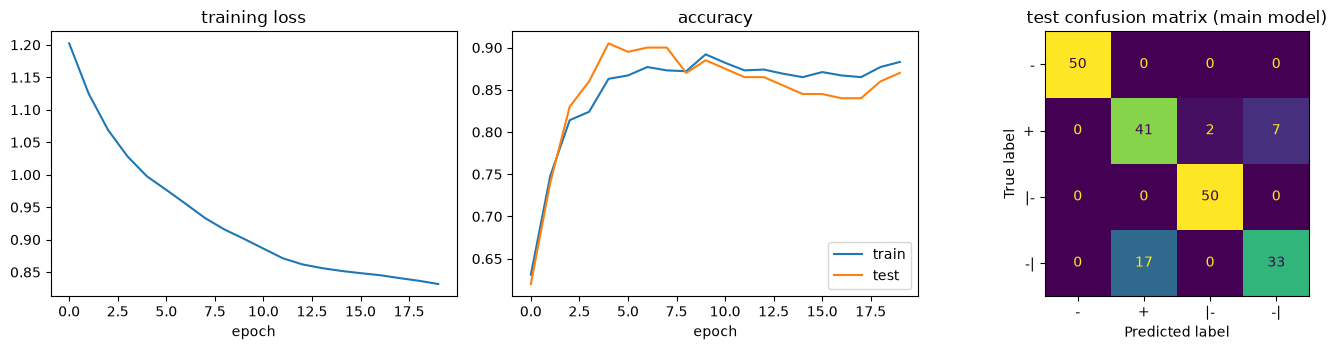

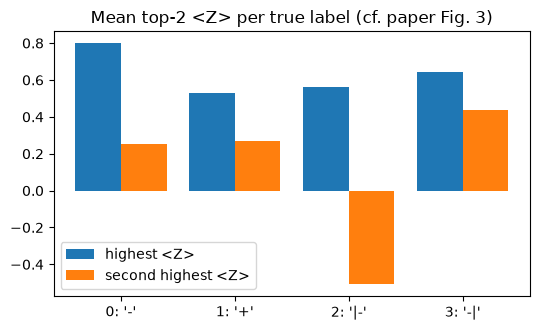

main model: train acc 0.883, test acc 0.870   (paper: 0.885 / 0.875)


In [8]:
def softmax_ce(z, y):
    z = z - anp.max(z, axis=1, keepdims=True)
    lp = z - anp.log(anp.sum(anp.exp(z), axis=1, keepdims=True))
    return -anp.sum(lp[anp.arange(len(y)), y])
loss_batch = lambda w, th, x, y: softmax_ce(qnn16(x, w, th), y) / len(y)
grad_params = grad(loss_batch, argnum=(0, 1))

class Adam:
    def __init__(s, lr, b1=.9, b2=.999, eps=1e-8): s.lr, s.b1, s.b2, s.eps, s.m, s.t = lr, b1, b2, eps, None, 0
    def step(s, ps, gs):
        if s.m is None: s.m = [np.zeros_like(p) for p in ps]; s.v = [np.zeros_like(p) for p in ps]
        s.t += 1; out = []
        for i, (p, g) in enumerate(zip(ps, gs)):
            s.m[i] = s.b1 * s.m[i] + (1 - s.b1) * g; s.v[i] = s.b2 * s.v[i] + (1 - s.b2) * g * g
            out.append(p - s.lr * (s.m[i] / (1 - s.b1 ** s.t)) / (np.sqrt(s.v[i] / (1 - s.b2 ** s.t)) + s.eps))
        return out

predict_qnn = lambda x16, w, th: np.argmax(np.asarray(qnn16(x16, w, th)), axis=1)
def train_qnn(seed, epochs=EPOCHS, lr=LR, bs=BATCH, verbose=True):
    rg = np.random.default_rng(seed)
    w = rg.normal(0, W_INIT, (L, NQ, 3)); th = rg.uniform(0, 2 * np.pi, (L, NQ, 3)); opt = Adam(lr); hist = []
    for ep in range(epochs):
        perm = rg.permutation(len(X_tr))
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; g = grad_params(w, th, X_tr[idx], y_tr[idx]); w, th = opt.step([w, th], list(g))
        hist.append((float(loss_batch(w, th, X_tr, y_tr)), (predict_qnn(X_tr, w, th) == y_tr).mean(), (predict_qnn(X_te, w, th) == y_te).mean()))
        if verbose and (ep % 5 == 4 or ep == 0): print(f"seed {seed} epoch {ep+1:2d}  loss {hist[-1][0]:.3f}  train acc {hist[-1][1]:.3f}  test acc {hist[-1][2]:.3f}")
    return w, th, np.array(hist)

t = time.time()
W_MAIN, TH_MAIN, hist_main = train_qnn(SEED)
print("training time %.0f s" % (time.time() - t))
acc_tr_main, acc_te_main = hist_main[-1, 1], hist_main[-1, 2]
seed_accs = [(acc_tr_main, acc_te_main)]
for sd in TRAIN_SEEDS[1:]:
    _, _, h = train_qnn(sd, verbose=False); seed_accs.append((h[-1, 1], h[-1, 2]))
seed_accs = np.array(seed_accs)
print("train acc %.3f +- %.3f | test acc %.3f +- %.3f over seeds %s" % (seed_accs[:, 0].mean(), seed_accs[:, 0].std(), seed_accs[:, 1].mean(), seed_accs[:, 1].std(), TRAIN_SEEDS))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(hist_main[:, 0]); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist_main[:, 1], label="train"); ax[1].plot(hist_main[:, 2], label="test"); ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
pred_te = predict_qnn(X_te, W_MAIN, TH_MAIN)
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=CLASS_NAMES).plot(ax=ax[2], colorbar=False); ax[2].set_title("test confusion matrix (main model)")
plt.tight_layout(); plt.show()

# Fig. 3 of the paper: average highest / second-highest <Z> per true label (training set)
Z_tr = np.asarray(qnn16(X_tr, W_MAIN, TH_MAIN)); srt = -np.sort(-Z_tr, axis=1)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.bar(np.arange(4) - .2, [srt[y_tr == c, 0].mean() for c in range(4)], .4, label="highest <Z>")
ax.bar(np.arange(4) + .2, [srt[y_tr == c, 1].mean() for c in range(4)], .4, label="second highest <Z>")
ax.set_xticks(range(4)); ax.set_xticklabels([f"{c}: '{n}'" for c, n in enumerate(CLASS_NAMES)]); ax.set_title("Mean top-2 <Z> per true label (cf. paper Fig. 3)"); ax.legend(); plt.tight_layout(); plt.show()
pred0_tr = predict_qnn(X_tr, W_MAIN, TH_MAIN); pred0_te = pred_te
print("main model: train acc %.3f, test acc %.3f   (paper: 0.885 / 0.875)" % (acc_tr_main, acc_te_main))

## 5. Stage 1 - side-channel reconnaissance from a simulated power trace

Following Sec. IV-D / V-A of the paper: the circuit is transpiled to the AQT native gates `rz, r, rxx` with `optimization_level=0` (every gate is kept), and the pulse amplitudes are computed from the paper's formulas.
For ten qubits `a = [1, -1, 2, 3, 0, -2, -3, 0, -4, 4]`, `alpha_i = 1 + a_i/100`, `beta_ij = 10 + (a_i + a_j)/10` (the typeset formula is ambiguous; we read it as `(a_i + a_j)/10`).
A virtual `RZ` gives no pulse; `R(theta, phi)` = one 10 us pulse of amplitude `alpha_i * theta / pi` + 2 us idle; `RXX(theta)` = one 200 us pulse of amplitude `beta_ij * theta / pi` + 2 us idle.
The attacker builds the same trace for 24 benchmark circuits (4 or 8 qubits, 2/4/6/8 layers, `r` = default/1/2) with random angles in [0, 2 pi), keeps those with the same total duration (timing filter),
and picks the one with the smallest L2 distance on a 1 us grid.

In [9]:
A_COEF = [1, -1, 2, 3, 0, -2, -3, 0, -4, 4]
alpha_q = lambda i: 1 + A_COEF[i] / 100
beta_q = lambda i, j: 10 + (A_COEF[i] + A_COEF[j]) / 10

def logical_circuit(nq, nl, r, angles):
    """General-rotation layers + CNOT ring. angles: (nl, nq, 3) = (phi, theta, omega) of Rot. r=None -> PennyLane default ranges."""
    qc = QuantumCircuit(nq)
    for l in range(nl):
        for q in range(nq):
            p, t, o = angles[l, q]; qc.rz(p, q); qc.ry(t, q); qc.rz(o, q)      # Rot = RZ(omega) RY(theta) RZ(phi)
        rr = (l % (nq - 1)) + 1 if r is None else r
        for q in range(nq): qc.cx(q, (q + rr) % nq)
    return qc

def to_native(qc): return transpile(qc, basis_gates=["rz", "r", "rxx"], optimization_level=0)

def power_segments(qn):
    """(duration_us, amplitude) segments of the simulated AQT power trace of a native circuit (gates run sequentially)."""
    segs = [(2, 0.0)]                                            # t0 = 0, t1 = 2 us, P0 = P1 = 0
    for inst in qn.data:
        name, qs = inst.operation.name, [qn.find_bit(q).index for q in inst.qubits]
        if name == "rz": continue                               # virtual gate: no pulse
        if name == "r":   segs += [(10, alpha_q(qs[0]) * float(inst.operation.params[0]) / np.pi), (2, 0.0)]
        elif name == "rxx": segs += [(200, beta_q(*qs) * float(inst.operation.params[0]) / np.pi), (2, 0.0)]
        else: raise ValueError(name)
    return segs
total_time = lambda segs: sum(d for d, _ in segs)
def raster(segs):                                                # 1 us grid, forward filled (+ the end point)
    a = np.repeat([p for _, p in segs], [d for d, _ in segs]); return np.append(a, segs[-1][1])

BENCH = [(nq, nl, r) for nq in (4, 8) for nl in (2, 4, 6, 8) for r in (None, 1, 2)]       # 24 configurations
def rand_angles(nq, nl, rg): return rg.uniform(0, 2 * np.pi, (nl, nq, 3))
bench_T = {cfg: total_time(power_segments(to_native(logical_circuit(*cfg[:2], cfg[2], rand_angles(cfg[0], cfg[1], np.random.default_rng(0)))))) for cfg in BENCH}

def victim_angles(x16, w=None, th=None):
    w = W_MAIN if w is None else w; th = TH_MAIN if th is None else th
    return np.mod(w * np.reshape(np.tile(x16, 3), (L, NQ, 3)) + th, 2 * np.pi)       # CHOICE: wrapped to [0, 2 pi)

def identify(x16, rg):
    qv = to_native(logical_circuit(NQ, L, None, victim_angles(x16))); sv = power_segments(qv); Tv = total_time(sv); pv = raster(sv)
    cands = [cfg for cfg in BENCH if bench_T[cfg] == Tv]                              # 1) timing filter
    dist = {}
    for cfg in cands:                                                                 # 2) L2 distance on the 1 us grid
        pb = raster(power_segments(to_native(logical_circuit(cfg[0], cfg[1], cfg[2], rand_angles(cfg[0], cfg[1], rg)))))
        dist[cfg] = float(np.sqrt(np.sum((pb - pv) ** 2)))
    return Tv, cands, dist, sv

rg_p = np.random.default_rng(SEED)
Tv, cands, dist, sv0 = identify(X_tr[0], rg_p)
print("victim (4 qubits, 4 layers, r=default): total duration %d us; benchmarks with the same duration: %d of 24" % (Tv, len(cands)))
print(pd.DataFrame([dict(qubits=c[0], layers=c[1], r="default" if c[2] is None else c[2], L2_distance=round(d, 2)) for c, d in sorted(dist.items(), key=lambda kv: kv[1])]).to_string(index=False))
print("paper: 3 candidates left, distances 9.84 (best), 119.14, 132.14")

victim (4 qubits, 4 layers, r=default): total duration 4194 us; benchmarks with the same duration: 6 of 24
 qubits  layers       r  L2_distance
      4       4 default         7.82
      8       2 default       100.98
      8       2       1       107.67
      4       4       1       117.26
      4       4       2       121.09
      8       2       2       125.69
paper: 3 candidates left, distances 9.84 (best), 119.14, 132.14


structure recovered correctly in 50 / 50 victims | candidates after timing filter: [6]
distance to the right circuit: 9.60 +- 1.47 | to the runner-up: 100.5 +- 0.5
distance to the 4-qubit/4-layer circuit with r=1: 117.4 +- 0.5 (paper 119.14 or 132.14) | with r=2: 121.2 +- 0.5


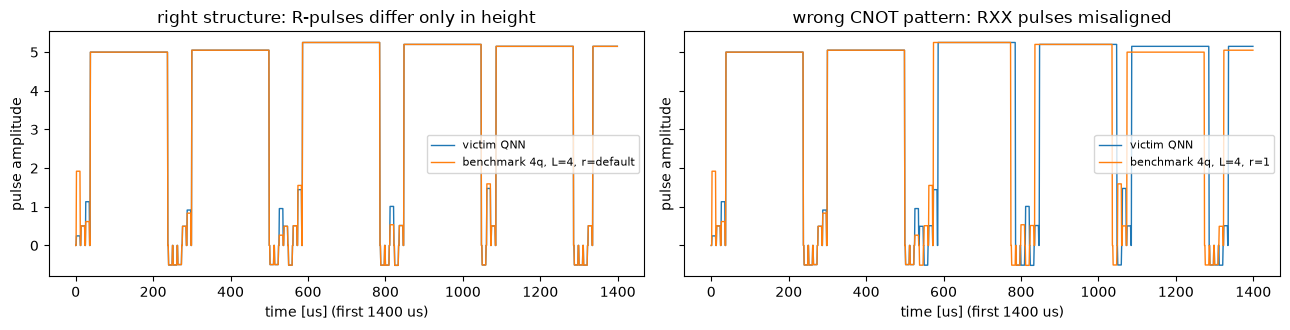

In [10]:
true_cfg = (NQ, L, None)
stats = []
for i in range(N_POWER_VICTIMS):
    _, cands_i, d_i, _ = identify(X_tr[i], rg_p)
    order = sorted(d_i.items(), key=lambda kv: kv[1])
    stats.append(dict(n_candidates=len(cands_i), best=order[0][0], d_best=order[0][1], d_second=order[1][1] if len(order) > 1 else np.nan, correct=order[0][0] == true_cfg, d_r1=d_i.get((NQ, L, 1)), d_r2=d_i.get((NQ, L, 2))))
df_pow = pd.DataFrame(stats)
print("structure recovered correctly in %d / %d victims | candidates after timing filter: %s" % (df_pow.correct.sum(), len(df_pow), sorted(set(df_pow.n_candidates))))
print("distance to the right circuit: %.2f +- %.2f | to the runner-up: %.1f +- %.1f" % (df_pow.d_best.mean(), df_pow.d_best.std(), df_pow.d_second.mean(), df_pow.d_second.std()))
print("distance to the 4-qubit/4-layer circuit with r=1: %.1f +- %.1f (paper 119.14 or 132.14) | with r=2: %.1f +- %.1f" % (df_pow.d_r1.mean(), df_pow.d_r1.std(), df_pow.d_r2.mean(), df_pow.d_r2.std()))

# power-trace figure (cf. paper Fig. 13-17): victim vs right benchmark vs a wrong entangling pattern
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
pv = raster(sv0)
for ax, cfg in zip(axes, [true_cfg, (NQ, L, 1)]):
    pb = raster(power_segments(to_native(logical_circuit(cfg[0], cfg[1], cfg[2], rand_angles(cfg[0], cfg[1], np.random.default_rng(1))))))
    n = min(len(pv), len(pb)); sl = slice(0, min(n, 1400))
    ax.plot(pv[sl], lw=1, label="victim QNN"); ax.plot(pb[sl], lw=1, label=f"benchmark {cfg[0]}q, L={cfg[1]}, r={'default' if cfg[2] is None else cfg[2]}")
    ax.set_xlabel("time [us] (first 1400 us)"); ax.set_ylabel("pulse amplitude"); ax.legend(fontsize=8)
axes[0].set_title("right structure: R-pulses differ only in height"); axes[1].set_title("wrong CNOT pattern: RXX pulses misaligned")
plt.tight_layout(); plt.show()

## 6. Hardware crosstalk factors from the published bit-strings (Appendix B)

The attacker needs the crosstalk factor `f_j = theta_eff / theta_theo` per listening ion. Appendix B lists the 2000-shot bit-string counts of ten `RY(pi/2)` gates on ions 3, 5, 7, 9 (Table XV) and the resulting factors (Table IV). We cannot repeat the hardware run, but we can recompute the factors from the published counts as a consistency check of the paper's arithmetic, and test the linear model `f = 0.007 (ends) / 0.010 (inside)` against the published `00000` counts of the whole angle sweep (Table XVII).

,ion,p1 (counts),theta_eff [rad],f (recomputed),"f (paper, Table IV)"
0,2,0.0030,0.1096,0.0070,0.007
1,4,0.0225,0.3011,0.0096,0.010
2,6,0.0265,0.3270,0.0104,0.010
3,8,0.0215,0.2943,0.0094,0.010
4,10,0.0030,0.1096,0.0070,0.007


,angle,published_00000,linear_model
0,0.010 pi,1998,2000
1,0.125 pi,1986,1990
2,0.250 pi,1957,1960
3,0.375 pi,1935,1912
4,0.500 pi,1839,1846
5,0.625 pi,1731,1763
6,0.750 pi,1660,1668
7,0.875 pi,1516,1560
8,1.000 pi,1489,1445


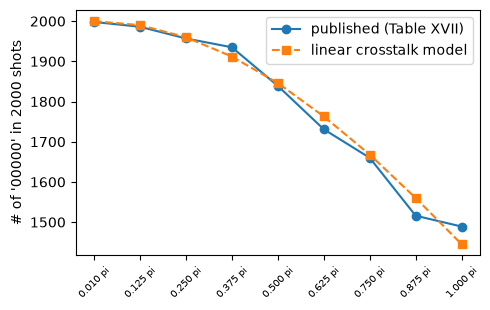

Table IV row recomputed within 0.001: True | linear model within 5 % of 2000 shots for all angles: True


In [11]:
# Table XV: counts over 2000 shots; bit i (from the right) = listening ion [2,4,6,8,10][i]
counts = {"00000": 1849, "00010": 44, "00100": 51, "01000": 42, "00001": 6, "10000": 6, "01100": 1, "00110": 1}
ions = [2, 4, 6, 8, 10]; N = sum(counts.values())
p1 = {ion: sum(c for b, c in counts.items() if b[::-1][i] == "1") / N for i, ion in enumerate(ions)}
theta_eff = {ion: 2 * np.arcsin(np.sqrt(p)) for ion, p in p1.items()}
n_nb = {2: 1, 4: 2, 6: 2, 8: 2, 10: 1}                    # number of active neighbours (ions 3,5,7,9 are driven)
theta_theo = {ion: n_nb[ion] * 10 * (np.pi / 2) for ion in ions}      # r = 10 gates of angle pi/2, normalised by the neighbour count
f_nb = {ion: theta_eff[ion] / theta_theo[ion] for ion in ions}
paper_f = {2: .007, 4: .010, 6: .010, 8: .010, 10: .007}      # Table IV, row pi/2
df_f = pd.DataFrame({"ion": ions, "p1 (counts)": [p1[i] for i in ions], "theta_eff [rad]": [theta_eff[i] for i in ions], "f (recomputed)": [f_nb[i] for i in ions], "f (paper, Table IV)": [paper_f[i] for i in ions]})
display(df_f.round(4))
f_ok = bool(np.all(np.abs(df_f["f (recomputed)"] - df_f["f (paper, Table IV)"]) < 0.001))

# linear model vs Table XVII (counts of 00000 for angle sweep). Edge ions: f=0.007, inner ions: 0.010
tab17 = {np.pi/100: 1998, np.pi/8: 1986, 2*np.pi/8: 1957, 3*np.pi/8: 1935, 4*np.pi/8: 1839, 5*np.pi/8: 1731, 6*np.pi/8: 1660, 7*np.pi/8: 1516, np.pi: 1489}
rows = []
for ang, pub in tab17.items():
    f_use = {2: .007, 4: .010, 6: .010, 8: .010, 10: .007}
    p0 = np.prod([1 - np.sin(f_use[i] * n_nb[i] * 10 * ang / 2) ** 2 for i in ions])
    rows.append(dict(angle=f"{ang/np.pi:.3f} pi", published_00000=pub, linear_model=round(2000 * p0)))
df_t17 = pd.DataFrame(rows); display(df_t17)
t17_ok = bool(np.all(np.abs(df_t17.published_00000 - df_t17.linear_model) <= 0.05 * 2000))
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot(range(9), df_t17.published_00000, "o-", label="published (Table XVII)"); ax.plot(range(9), df_t17.linear_model, "s--", label="linear crosstalk model")
ax.set_xticks(range(9)); ax.set_xticklabels(df_t17.angle, rotation=45, fontsize=7); ax.set_ylabel("# of '00000' in 2000 shots"); ax.legend(); plt.tight_layout(); plt.show()
print("Table IV row recomputed within 0.001:", f_ok, "| linear model within 5 % of 2000 shots for all angles:", t17_ok)

## 7. Stage 2 - adversarial examples with PGD

White-box PGD on the (state-vector) victim: `x <- Proj_eps( x + alpha * sign(grad_x CE) )`, `T = 100`, `alpha = 0.01`. For every sample the budget `eps` is raised from 0.1 to 1.0 in steps of 0.1 and the first `eps` for which the prediction differs
from the prediction on the clean input is recorded (Table VI). Perturbations live in the 16-dimensional PCA space (all three re-uploads of a feature move together). We stop a sample's PGD at the first iteration that changes the decision (`# CHOICE`).
A classical network of similar size (16-8-4 tanh MLP, 172 parameters, same Adam budget) is attacked with the very same routine for comparison.

PGD stage 2 on 1000 training samples: 139 s


,eps,samples,original_correct,label_flipping,samples_paper,correct_paper,flipped_paper,samples_scaled
0,0.1,76,75,0,63,54,5,63.0
1,0.2,57,56,0,87,81,3,87.0
2,0.3,97,86,0,92,90,0,92.0
3,0.4,155,147,0,81,77,1,81.0
4,0.5,225,216,1,87,83,0,87.0
5,0.6,142,140,0,104,103,0,104.0
6,0.7,60,56,0,88,87,0,88.0
7,0.8,51,49,0,83,79,0,83.0
8,0.9,44,43,0,71,59,0,71.0
9,1.0,17,13,0,84,78,0,84.0


PGD found an adversarial example for 924 / 1000 samples (92.4 %; paper 840/1000 = 84.0 %); none for 76 (paper: 160)
accuracy on these samples: clean 0.883 -> adversarial 0.003   (paper: 0.924 -> 0.0107)
mean minimal eps among broken samples: 0.48


pre-screening check on 6 failed samples: successes at any budget without pre-screening = 0


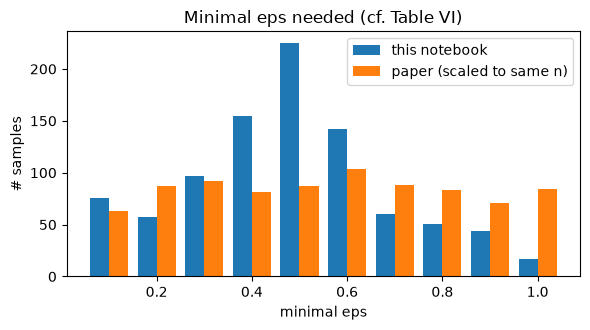

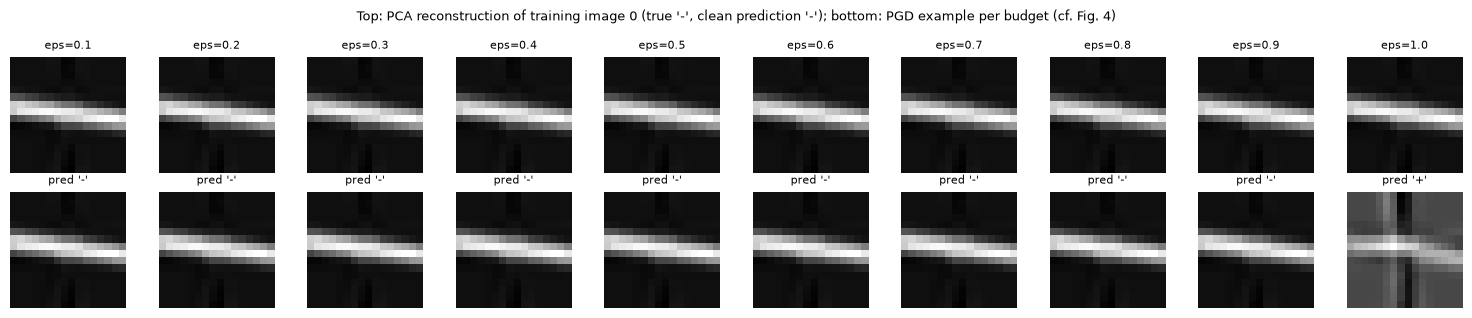

In [12]:
def pgd_min_eps(grad_fn, pred_fn, X, y, pred0, eps_grid=EPS_GRID, T=PGD_T, alpha=PGD_ALPHA, mask=None, prescreen=True):
    """Smallest eps in eps_grid for which sign-gradient PGD (optionally masked) changes the prediction. Returns (eps_min or nan, x_adv).
    prescreen=True (CHOICE, saves ~10x compute): samples for which PGD fails at the largest budget are declared 'no adversarial example' and not retried at smaller budgets."""
    n = len(X); eps_min = np.full(n, np.nan); X_adv = X.copy()
    def run(idx, eps):
        x0, yy, p0 = X[idx], y[idx], pred0[idx]
        x = x0.copy(); active = np.ones(len(idx), bool); won = np.zeros(len(idx), bool)
        for _ in range(T):
            ia = np.flatnonzero(active)
            if ia.size == 0: break
            s = np.sign(grad_fn(x[ia], yy[ia]))
            if mask is not None: s = s * mask
            x[ia] = x0[ia] + np.clip(x[ia] + alpha * s - x0[ia], -eps, eps)           # step, then projection on the l_inf ball
            fl = pred_fn(x[ia]) != p0[ia]
            won[ia[fl]] = True; active[ia[fl]] = False
        return won, x
    remaining = np.arange(n)
    if prescreen and len(eps_grid) > 1:
        won, _ = run(remaining, eps_grid[-1]); remaining = remaining[won]
    for eps in eps_grid:
        if remaining.size == 0: break
        won, x = run(remaining, eps)
        X_adv[remaining[won]] = x[won]; eps_min[remaining[won]] = eps; remaining = remaining[~won]
    return eps_min, X_adv
# gradient of the summed cross-entropy w.r.t. the 16-d input (true label), through all three re-uploads
gx16 = grad(lambda x, y: softmax_ce(qnn16(x, W_MAIN, TH_MAIN), y))
pred_fn_q = lambda x: predict_qnn(x, W_MAIN, TH_MAIN)

n2 = N_ATTACK_STAGE2
idx2 = np.arange(n2)                                     # first n2 training samples
X2, y2, p2 = X_tr[idx2], y_tr[idx2], pred0_tr[idx2]
t = time.time()
eps2, Xadv2 = pgd_min_eps(gx16, pred_fn_q, X2, y2, p2)
print("PGD stage 2 on %d training samples: %.0f s" % (n2, time.time() - t))

padv2 = pred_fn_q(Xadv2)
broken = ~np.isnan(eps2); orig_correct = (p2 == y2)
rows = []
for e in EPS_GRID:
    m = np.isclose(eps2, e)
    rows.append(dict(eps=e, samples=int(m.sum()), original_correct=int((m & orig_correct).sum()), label_flipping=int((m & ~orig_correct & (padv2 == y2)).sum())))
df_t6 = pd.DataFrame(rows); df_t6["samples_paper"] = [63, 87, 92, 81, 87, 104, 88, 83, 71, 84]; df_t6["correct_paper"] = [54, 81, 90, 77, 83, 103, 87, 79, 59, 78]; df_t6["flipped_paper"] = [5, 3, 0, 1, 0, 0, 0, 0, 0, 0]
df_t6["samples_scaled"] = (df_t6.samples_paper * n2 / 1000).round(1)
display(df_t6)
succ2 = broken.mean(); acc_clean2 = (p2 == y2).mean(); acc_adv2 = (padv2 == y2).mean()
print("PGD found an adversarial example for %d / %d samples (%.1f %%; paper 840/1000 = 84.0 %%); none for %d (paper: 160)" % (broken.sum(), n2, 100 * succ2, (~broken).sum()))
print("accuracy on these samples: clean %.3f -> adversarial %.3f   (paper: 0.924 -> 0.0107)" % (acc_clean2, acc_adv2))
print("mean minimal eps among broken samples: %.2f" % np.nanmean(eps2))
# spot check of the pre-screening shortcut: samples that failed at eps = 1.0 are retried at every smaller budget
fails = np.flatnonzero(~broken)[:6]
if len(fails):
    e_chk, _ = pgd_min_eps(gx16, pred_fn_q, X2[fails], y2[fails], p2[fails], prescreen=False)
    print("pre-screening check on %d failed samples: successes at any budget without pre-screening = %d" % (len(fails), int((~np.isnan(e_chk)).sum())))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(np.array(EPS_GRID) - .02, df_t6.samples, .04, label="this notebook"); ax.bar(np.array(EPS_GRID) + .02, df_t6.samples_scaled, .04, label="paper (scaled to same n)")
ax.set_xlabel("minimal eps"); ax.set_ylabel("# samples"); ax.set_title("Minimal eps needed (cf. Table VI)"); ax.legend()
plt.tight_layout(); plt.show()
# image-space view (cf. Fig. 4): one sample, adversarial example re-computed at every fixed budget, mapped back through the PCA
i0 = int(np.flatnonzero(broken & orig_correct)[0]) if (broken & orig_correct).any() else 0
panels = []
for e in EPS_GRID:
    em, xa = pgd_min_eps(gx16, pred_fn_q, X2[i0:i0+1], y2[i0:i0+1], p2[i0:i0+1], eps_grid=[e])
    panels.append((e, pca.inverse_transform(xa)[0].reshape(16, 16), pred_fn_q(xa)[0]))
fig, axes = plt.subplots(2, 10, figsize=(15, 3.2))
orig_img = pca.inverse_transform(X2[i0:i0+1])[0].reshape(16, 16)
for j, (e, im, pr) in enumerate(panels):
    axes[0, j].imshow(orig_img, cmap="gray"); axes[0, j].axis("off"); axes[0, j].set_title(f"eps={e}", fontsize=8)
    axes[1, j].imshow(im, cmap="gray"); axes[1, j].axis("off"); axes[1, j].set_title(f"pred '{CLASS_NAMES[pr]}'", fontsize=8)
fig.suptitle(f"Top: PCA reconstruction of training image {i0} (true '{CLASS_NAMES[y2[i0]]}', clean prediction '{CLASS_NAMES[p2[i0]]}'); bottom: PGD example per budget (cf. Fig. 4)", fontsize=9)
plt.tight_layout(); plt.show()

In [13]:
# ---- classical comparison: 16-8-4 tanh MLP with the same inputs, optimiser and budget ----
def mlp_logits(P, x): return anp.tanh(x @ P[0] + P[1]) @ P[2] + P[3]
mlp_loss = lambda P0, P1, P2, P3, x, y: softmax_ce(mlp_logits([P0, P1, P2, P3], x), y) / len(y)
mlp_grad = grad(mlp_loss, argnum=(0, 1, 2, 3))
rg = np.random.default_rng(SEED)
P_mlp = [rg.normal(0, .5, (16, 8)), np.zeros(8), rg.normal(0, .5, (8, 4)), np.zeros(4)]
opt = Adam(LR)
for ep in range(EPOCHS):
    perm = rg.permutation(len(X_tr))
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i+BATCH]; P_mlp = opt.step(P_mlp, list(mlp_grad(*P_mlp, X_tr[idx], y_tr[idx])))
pred_mlp = lambda x: np.argmax(np.asarray(mlp_logits(P_mlp, x)), axis=1)
print("MLP parameters:", sum(p.size for p in P_mlp), "| train acc %.3f | test acc %.3f" % ((pred_mlp(X_tr) == y_tr).mean(), (pred_mlp(X_te) == y_te).mean()))
gx_mlp = grad(lambda x, y: softmax_ce(mlp_logits(P_mlp, x), y))
pm0 = pred_mlp(X2)
eps_m, Xadv_m = pgd_min_eps(gx_mlp, pred_mlp, X2, y2, pm0)
succ_m = (~np.isnan(eps_m)).mean(); acc_adv_m = (pred_mlp(Xadv_m) == y2).mean()
print("classical MLP: PGD success %.1f %% | accuracy clean %.3f -> adversarial %.3f | mean minimal eps %.2f" % (100 * succ_m, (pm0 == y2).mean(), acc_adv_m, np.nanmean(eps_m)))
df_cmp = pd.DataFrame([dict(model="QNN (96 params)", success_rate=succ2, acc_clean=acc_clean2, acc_adv=acc_adv2, mean_eps=np.nanmean(eps2)),
                       dict(model="MLP 16-8-4 (172 params)", success_rate=succ_m, acc_clean=(pm0 == y2).mean(), acc_adv=acc_adv_m, mean_eps=np.nanmean(eps_m))])
display(df_cmp.round(3))

MLP parameters: 172 | train acc 1.000 | test acc 1.000


classical MLP: PGD success 100.0 % | accuracy clean 1.000 -> adversarial 0.000 | mean minimal eps 0.34


,model,success_rate,acc_clean,acc_adv,mean_eps
0,QNN (96 params),0.924,0.883,0.003,0.484
1,MLP 16-8-4 (172 params),1.000,1.000,0.000,0.344


## 8. Stage 3 - masked PGD and the crosstalk attack (emulated)

**Masked PGD.** On the trapped-ion device only `RY` rotations leak (virtual `RZ` gates produce no pulse), so the perturbation of the 48-entry expanded input is restricted to the middle element of every `(RZ, RY, RZ)` triple (indices 1, 4, 7, ..., 46). Because the 16 features are
spread over the 16 `RY` slots in the order `[2,5,8,11,14,1,4,7,10,13,16,3,6,9,12,15]` (Table V), each feature is perturbable exactly once. Only samples that the QNN classifies correctly are attacked (paper: 885 of 1000).

**Crosstalk plan.** The needed shift of an `RY` angle is `d_theta = w * (x_adv - x)`. The attacker fires `RY(gamma)` on *both* neighbouring ions with `gamma = d_theta / (2 f)` (`f = 0.01`), saturated at `pi` and split into
`RY(+-pi)` pulses plus a residual. The victim qubits sit on ions 3, 5, 7, 9; ion 4 neighbours both ion 3 and ion 5, so an attack on one victim qubit also disturbs the other one (the paper points this out as a limitation).

**Emulated device.** The real chip is replaced by (i) the linear crosstalk model `theta_induced = f_pair * gamma` with the *per-pair* couplings `F_TRUE` (slightly different from the attacker's assumed `f = 0.01`, and including the collateral kicks),
and (ii) a generic trapped-ion noise model in Qiskit Aer (depolarising errors on the native `r` and `rxx` gates, read-out error, 2000 shots). The induced rotations are noise-free `ry` gates inserted at the time slot of the targeted `RY` gate.
We assert that this 4-qubit *effective* circuit equals the explicit 9-qubit circuit (victim ions 3, 5, 7, 9 + neighbours 2, 4, 6, 8, 10 with the attacker pulses and the crosstalk couplings) in the noiseless case.

RY encoding order reproduces Table V: [2, 5, 8, 11, 14, 1, 4, 7, 10, 13, 16, 3, 6, 9, 12, 15]


masked PGD on 883 correctly classified samples: 113 s


,eps,samples,samples_paper,samples_paper_scaled
0,0.1,21,33,32.9
1,0.2,24,28,27.9
2,0.3,36,31,30.9
3,0.4,38,50,49.9
4,0.5,32,40,39.9
5,0.6,36,28,27.9
6,0.7,55,35,34.9
7,0.8,70,28,27.9
8,0.9,71,33,32.9
9,1.0,99,32,31.9


masked PGD succeeds for 482 / 883 = 54.6 %  (paper 338/885 = 38.2 %; unconstrained PGD here: 92.4 %)


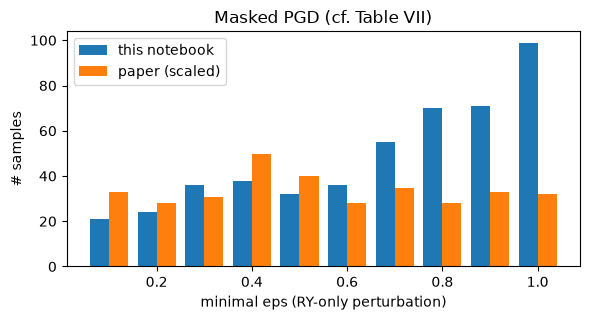

In [14]:
MASK48 = np.zeros(48); MASK48[1::3] = 1.0                       # middle element of each (RZ, RY, RZ) triple
assert [int(i) for i in np.flatnonzero(MASK48)][:3] == [1, 4, 7]
# check of Table V: the feature index encoded in the RY slot of gate g (layer-major, qubit-minor)
ry_order = [(3 * g + 1) % 16 + 1 for g in range(L * NQ)]
assert ry_order == [2, 5, 8, 11, 14, 1, 4, 7, 10, 13, 16, 3, 6, 9, 12, 15]
print("RY encoding order reproduces Table V:", ry_order)

gx48 = grad(lambda x, y: softmax_ce(qnn48(x, W_MAIN, TH_MAIN), y))
pred_fn_48 = lambda x: np.argmax(np.asarray(qnn48(x, W_MAIN, TH_MAIN)), axis=1)

cidx = np.flatnonzero(pred0_tr == y_tr)[:N_ATTACK_STAGE3]        # correctly classified training samples
X48 = np.tile(X_tr[cidx], 3); y3 = y_tr[cidx]; p3 = pred0_tr[cidx]
t = time.time()
eps3, Xadv48 = pgd_min_eps(gx48, pred_fn_48, X48, y3, p3, mask=MASK48)
print("masked PGD on %d correctly classified samples: %.0f s" % (len(cidx), time.time() - t))
assert np.allclose((Xadv48 - X48)[:, MASK48 == 0], 0)          # nothing outside the RY slots moved
ok3 = ~np.isnan(eps3)
paper_t7 = [33, 28, 31, 50, 40, 28, 35, 28, 33, 32]
df_t7 = pd.DataFrame({"eps": EPS_GRID, "samples": [int(np.isclose(eps3, e).sum()) for e in EPS_GRID], "samples_paper": paper_t7})
df_t7["samples_paper_scaled"] = (df_t7.samples_paper * len(cidx) / 885).round(1)
display(df_t7)
succ3 = ok3.mean()
print("masked PGD succeeds for %d / %d = %.1f %%  (paper 338/885 = 38.2 %%; unconstrained PGD here: %.1f %%)" % (ok3.sum(), len(cidx), 100 * succ3, 100 * succ2))
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar(np.array(EPS_GRID) - .02, df_t7.samples, .04, label="this notebook"); ax.bar(np.array(EPS_GRID) + .02, df_t7.samples_paper_scaled, .04, label="paper (scaled)")
ax.set_xlabel("minimal eps (RY-only perturbation)"); ax.set_ylabel("# samples"); ax.set_title("Masked PGD (cf. Table VII)"); ax.legend(); plt.tight_layout(); plt.show()

In [15]:
# ---------------- crosstalk plan ----------------
def pulse_train(gamma):
    s, a = np.sign(gamma), abs(gamma); n = int(a // np.pi); res = a - n * np.pi          # saturation at pi, then RY(+-pi) pulses + residual
    return [s * np.pi] * n + ([s * res] if res > 1e-12 else [])

def plan_crosstalk(x48, xadv48):
    """For every RY gate g=(layer, qubit): pulse angles fired simultaneously on both neighbouring ions of ion ION_POS[q]."""
    out = {}
    for g in range(L * NQ):
        l, q = divmod(g, NQ)
        d_theta = W_MAIN[l, q, 1] * (xadv48[3*g+1] - x48[3*g+1])                           # desired change of the RY angle
        out[g] = pulse_train(d_theta / (2 * F_ASSUMED))
    return out

def induced_angles(g, pulses, collateral=True):
    """RY angle induced on each victim wire by the pulses fired next to victim qubit g % NQ."""
    ion = ION_POS[g % NQ]; ind = np.zeros(NQ)
    for a in pulses:
        for n in (ion - 1, ion + 1):
            for u_idx, u in enumerate(ION_POS):
                if (n, u) in F_TRUE and (collateral or u == ion): ind[u_idx] += F_TRUE[(n, u)] * a
    return ind

# native CNOT = template taken from the transpiler (rz, r, rxx)
_cx = QuantumCircuit(2); _cx.cx(0, 1)
CX_TEMPLATE = [(i.operation.name, [float(p) for p in i.operation.params], [_cx.find_bit(q).index for q in i.qubits]) for i in to_native(_cx).data]
def native_cx(qc, c, t):
    m = {0: c, 1: t}
    for name, prm, qs in CX_TEMPLATE:
        if name == "r": qc.r(prm[0], prm[1], m[qs[0]])
        elif name == "rz": qc.rz(prm[0], m[qs[0]])
        elif name == "rxx": qc.rxx(prm[0], m[qs[0]], m[qs[1]])

def build_effective(x48, variant, xadv48=None):
    """4-qubit circuit in AQT native gates; variants: clean | adv | xtalk (full device model) | xtalk_target (no collateral kicks)."""
    x = xadv48 if variant == "adv" else x48
    plan = plan_crosstalk(x48, xadv48) if variant.startswith("xtalk") else None
    qc = QuantumCircuit(NQ)
    for l in range(L):
        for q in range(NQ):
            g = l * NQ + q
            ph, t_, om = [W_MAIN[l, q, j] * x[3*g+j] + TH_MAIN[l, q, j] for j in range(3)]
            qc.rz(ph, q); qc.r(t_, np.pi / 2, q)                       # RY(theta) as the native R(theta, pi/2)
            if plan is not None:
                for u, a in enumerate(induced_angles(g, plan[g], collateral=(variant == "xtalk"))):
                    if abs(a) > 1e-12: qc.ry(a, u)                      # crosstalk-induced rotation (not a gate the victim executes)
            qc.rz(om, q)
        for q in range(NQ): native_cx(qc, q, (q + RANGES[l]) % NQ)
    return qc

def build_physical(x48, xadv48):
    """Explicit 9-ion circuit: wire = ion - 2. Victim gates + attacker RY pulses on neighbours + crosstalk couplings."""
    wire = lambda ion: ion - 2; vw = [wire(i) for i in ION_POS]
    plan = plan_crosstalk(x48, xadv48); qc = QuantumCircuit(9)
    for l in range(L):
        for q in range(NQ):
            g = l * NQ + q
            ph, t_, om = [W_MAIN[l, q, j] * x48[3*g+j] + TH_MAIN[l, q, j] for j in range(3)]
            qc.rz(ph, vw[q]); qc.r(t_, np.pi / 2, vw[q])
            ion = ION_POS[q]
            for a in plan[g]:
                for n in (ion - 1, ion + 1):
                    qc.ry(a, wire(n))                                   # attacker pulse on the neighbouring ion
                    for u in ION_POS:
                        if (n, u) in F_TRUE: qc.ry(F_TRUE[(n, u)] * a, wire(u))      # leaked rotation on the adjacent victim ion
            qc.rz(om, vw[q])
        for q in range(NQ):
            c, t2 = vw[q], vw[(q + RANGES[l]) % NQ]
            for name, prm, qs in CX_TEMPLATE:
                m = {0: c, 1: t2}
                if name == "r": qc.r(prm[0], prm[1], m[qs[0]])
                elif name == "rz": qc.rz(prm[0], m[qs[0]])
                else: qc.rxx(prm[0], m[qs[0]], m[qs[1]])
    return qc, vw

def z_exp(qc, wires):
    sv = Statevector(qc); return np.array([float(sv.probabilities([w_])[0] - sv.probabilities([w_])[1]) for w_ in wires])

# ---------------- equivalence checks ----------------
sel_pool = np.flatnonzero(ok3)
sel = np.sort(RNG.choice(sel_pool, size=min(N_HW, len(sel_pool)), replace=False))
k0 = sel[0]
qc_c = build_effective(X48[k0], "clean"); qc_a = build_effective(X48[k0], "adv", Xadv48[k0])
assert np.allclose(z_exp(qc_c, range(NQ)), np.stack(victim_qnode(X48[k0], W_MAIN, TH_MAIN)), atol=1e-8)       # native circuit == QNode
assert np.allclose(z_exp(qc_a, range(NQ)), np.stack(victim_qnode(Xadv48[k0], W_MAIN, TH_MAIN)), atol=1e-8)
qc_x = build_effective(X48[k0], "xtalk", Xadv48[k0]); qc_phys, vwires = build_physical(X48[k0], Xadv48[k0])
assert np.allclose(z_exp(qc_x, range(NQ)), z_exp(qc_phys, vwires), atol=1e-8)                                # effective == explicit 9-ion circuit
print("native circuits == PennyLane QNode, effective crosstalk circuit == explicit 9-ion circuit (max |diff| < 1e-8)")
print("explicit 9-ion circuit: %d gates (attacker pulses included); effective 4-qubit circuit: %d gates" % (sum(qc_phys.count_ops().values()), sum(qc_x.count_ops().values())))
n_pulses = [len(p) for p in plan_crosstalk(X48[k0], Xadv48[k0]).values()]
print("RY pulses per targeted gate for this sample:", n_pulses, "| total", sum(n_pulses))

native circuits == PennyLane QNode, effective crosstalk circuit == explicit 9-ion circuit (max |diff| < 1e-8)
explicit 9-ion circuit: 375 gates (attacker pulses included); effective 4-qubit circuit: 168 gates
RY pulses per targeted gate for this sample: [4, 6, 1, 3, 3, 9, 1, 1, 1, 7, 1, 1, 3, 1, 1, 1] | total 44


In [16]:
# ---------------- emulated device: noisy Aer simulation ----------------
def make_sim(scale, seed=SEED):
    nm = NoiseModel()
    if scale > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(NOISE["p1"] * scale, 1), ["r"])
        nm.add_all_qubit_quantum_error(depolarizing_error(NOISE["p2"] * scale, 2), ["rxx"])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - NOISE["ro"] * scale, NOISE["ro"] * scale], [NOISE["ro"] * scale, 1 - NOISE["ro"] * scale]]))
    return AerSimulator(method="density_matrix", noise_model=nm, seed_simulator=seed)

def run_noisy(circs, scale):
    sim = make_sim(scale); mc = []
    for c in circs:
        m = c.copy(); m.measure_all(); mc.append(m)
    res = sim.run(mc, shots=SHOTS).result(); out = np.zeros((len(circs), NQ))
    for i in range(len(circs)):
        for key, cnt in res.get_counts(i).items():
            bits = key.replace(" ", "")[::-1]
            out[i] += cnt * np.array([1 - 2 * int(bits[q]) for q in range(NQ)])
    return out / SHOTS

VARIANTS = ["clean", "adv", "xtalk", "xtalk_target"]
t = time.time()
circs = {v: [build_effective(X48[k], v, Xadv48[k]) for k in sel] for v in VARIANTS}
ideal = {v: np.array([z_exp(c, range(NQ)) for c in circs[v]]) for v in VARIANTS}           # noiseless state-vector expectation values
hw = {v: run_noisy(circs[v], 1.0) for v in VARIANTS}                                         # noisy, finite-shot "hardware" emulation
ysel = y3[sel]
acc = lambda E: float((np.argmax(E, axis=1) == ysel).mean())
df_t8 = pd.DataFrame([dict(input={"clean": "clean image", "adv": "adversarial image (masked PGD)", "xtalk": "crosstalk image (full device model)", "xtalk_target": "crosstalk image (target-only, no collateral)"}[v],
                           accuracy_noiseless=acc(ideal[v]), accuracy_noisy_emulation=acc(hw[v]),
                           paper_hardware={"clean": .64, "adv": .56, "xtalk": .68}.get(v, np.nan)) for v in VARIANTS])
display(df_t8.round(3)); print("emulation time %.0f s for %d samples x %d variants" % (time.time() - t, len(sel), len(VARIANTS)))

# Table IX analogue: mean absolute error between expectation-value vectors
src = {"hw_clean": hw["clean"], "hw_adv": hw["adv"], "hw_crosstalk": hw["xtalk"], "model_clean": ideal["clean"], "model_adv": ideal["adv"]}
paper_t9 = {("hw_adv", "hw_crosstalk"): .1236, ("hw_clean", "hw_crosstalk"): .1270, ("hw_clean", "hw_adv"): .1452, ("model_clean", "model_adv"): .1682, ("hw_adv", "model_adv"): .2532,
            ("hw_clean", "model_adv"): .2745, ("hw_crosstalk", "model_adv"): .2831, ("hw_clean", "model_clean"): .3086, ("hw_crosstalk", "model_clean"): .3294, ("hw_adv", "model_clean"): .3534}
rows = [dict(pair=f"{a} vs {b}", MAE_emulation=float(np.mean(np.abs(src[a] - src[b]))), MAE_paper=v) for (a, b), v in paper_t9.items()]
df_t9 = pd.DataFrame(rows).sort_values("MAE_emulation").reset_index(drop=True); display(df_t9.round(4))
smallest_pair = df_t9.pair[0]; print("smallest MAE in the emulation:", smallest_pair, "| paper: hw_adv vs hw_crosstalk")

# how much of the intended angle shift reaches the target RY gate? (induced / desired)
ratios = []
for k in sel:
    plan = plan_crosstalk(X48[k], Xadv48[k])
    for g, pul in plan.items():
        l, q = divmod(g, NQ); want = W_MAIN[l, q, 1] * (Xadv48[k][3*g+1] - X48[k][3*g+1])
        if abs(want) > 1e-6: ratios.append(induced_angles(g, pul)[q] / want)
print("induced / desired RY shift: median %.2f (ends of the chain are weaker: couplings 0.007 vs 0.010)" % np.median(ratios))

# noise sweep
rows = []
for sc_ in [0.0, 0.5, 1.0, 2.0]:
    r_ = {v: acc(run_noisy(circs[v], sc_)) for v in ["clean", "adv", "xtalk"]}; r_["noise_scale"] = sc_; rows.append(r_)
display(pd.DataFrame(rows)[["noise_scale", "clean", "adv", "xtalk"]].round(3))

,input,accuracy_noiseless,accuracy_noisy_emulation,paper_hardware
0,clean image,1.00,0.90,0.64
1,adversarial image (masked PGD),0.00,0.26,0.56
2,crosstalk image (full device model),0.58,0.44,0.68
3,"crosstalk image (target-only, no collateral)",0.94,0.38,NaN


emulation time 11 s for 50 samples x 4 variants


,pair,MAE_emulation,MAE_paper
0,hw_adv vs hw_crosstalk,0.0439,0.1236
1,hw_adv vs model_adv,0.1196,0.2532
2,hw_clean vs hw_crosstalk,0.1215,0.1270
3,hw_clean vs hw_adv,0.1333,0.1452
4,hw_crosstalk vs model_adv,0.1352,0.2831
5,hw_clean vs model_adv,0.1526,0.2745
6,hw_clean vs model_clean,0.1568,0.3086
7,model_clean vs model_adv,0.1910,0.1682
8,hw_crosstalk vs model_clean,0.2648,0.3294
9,hw_adv vs model_clean,0.2722,0.3534


smallest MAE in the emulation: hw_adv vs hw_crosstalk | paper: hw_adv vs hw_crosstalk
induced / desired RY shift: median 0.85 (ends of the chain are weaker: couplings 0.007 vs 0.010)


,noise_scale,clean,adv,xtalk
0,0.0,1.00,0.44,0.60
1,0.5,0.98,0.26,0.60
2,1.0,0.90,0.26,0.44
3,2.0,0.90,0.30,0.54


### Is the conclusion specific to this victim? (other training seeds)

The attack statistics depend on how sharply the trained QNN reacts to its inputs. In the full run the other trained victims (seeds 43, 44) are attacked in the same way on the first 200 training samples (clean accuracy, unconstrained and masked PGD success rate).

In [17]:
rows = [dict(seed=SEED, train_acc=acc_tr_main, test_acc=acc_te_main, pgd_success=succ2, masked_pgd_success=succ3)]
if len(TRAIN_SEEDS) > 1:
    for sd in TRAIN_SEEDS[1:]:
        w_s, th_s, h_s = train_qnn(sd, verbose=False)
        pr = lambda x, w_=w_s, t_=th_s: np.argmax(np.asarray(qnn48(x, w_, t_)), axis=1)
        g_u = grad(lambda x, y, w_=w_s, t_=th_s: softmax_ce(qnn48(expand(x), w_, t_), y)); g_m = grad(lambda x, y, w_=w_s, t_=th_s: softmax_ce(qnn48(x, w_, t_), y))
        Xs = X_tr[:200]; ys = y_tr[:200]; p_s = pr(np.tile(Xs, 3)); e_u, _ = pgd_min_eps(g_u, lambda x, f=pr: f(np.tile(x, 3)), Xs, ys, p_s)
        ci = np.flatnonzero(p_s == ys); e_m, _ = pgd_min_eps(g_m, pr, np.tile(Xs[ci], 3), ys[ci], p_s[ci], mask=MASK48)
        rows.append(dict(seed=sd, train_acc=h_s[-1, 1], test_acc=h_s[-1, 2], pgd_success=float((~np.isnan(e_u)).mean()), masked_pgd_success=float((~np.isnan(e_m)).mean())))
df_seeds = pd.DataFrame(rows); display(df_seeds.round(3))
if len(rows) == 1: print("FAST_MODE: only the main victim is attacked; set FAST_MODE = False to add seeds 43 and 44.")

,seed,train_acc,test_acc,pgd_success,masked_pgd_success
0,42,0.883,0.87,0.924,0.546
1,43,0.831,0.85,0.810,0.544
2,44,0.970,0.95,0.975,0.802


## Quantum Circuit Architecture

Everything below is drawn from the objects that were actually executed in this notebook:

* **Victim QNN** - the PennyLane QNode `victim_qnode` (clean and adversarial inputs use the same circuit; only the classical angles change). Its Qiskit twin (logical gates, then the AQT-native compilation used for the power trace and for the noisy emulation) is drawn too and asserted equal to the QNode.
* **Benchmark circuits of stage 1** - 24 circuits (4 or 8 qubits, 2/4/6/8 layers, `r` = default/1/2). Their power traces were computed; they are not state-simulated. The three 4-qubit/4-layer ones are drawn, all 24 are tabulated.
* **Attack circuits of stage 3** - the 4-qubit effective crosstalk circuit executed by Aer (with the induced `ry` rotations), and the explicit 9-ion circuit with the attacker pulses that was used for the equivalence check.

Assumptions where the paper is silent: general rotation `Rot = RZ(omega) RY(theta) RZ(phi)` as in PennyLane; CNOT ranges from the PennyLane template; native `R(theta, pi/2)` for `RY`; CNOT compiled by the Qiskit translator to one `RXX(pi/2)` plus single-qubit `R` gates; measurement of all four qubits in the Z basis.

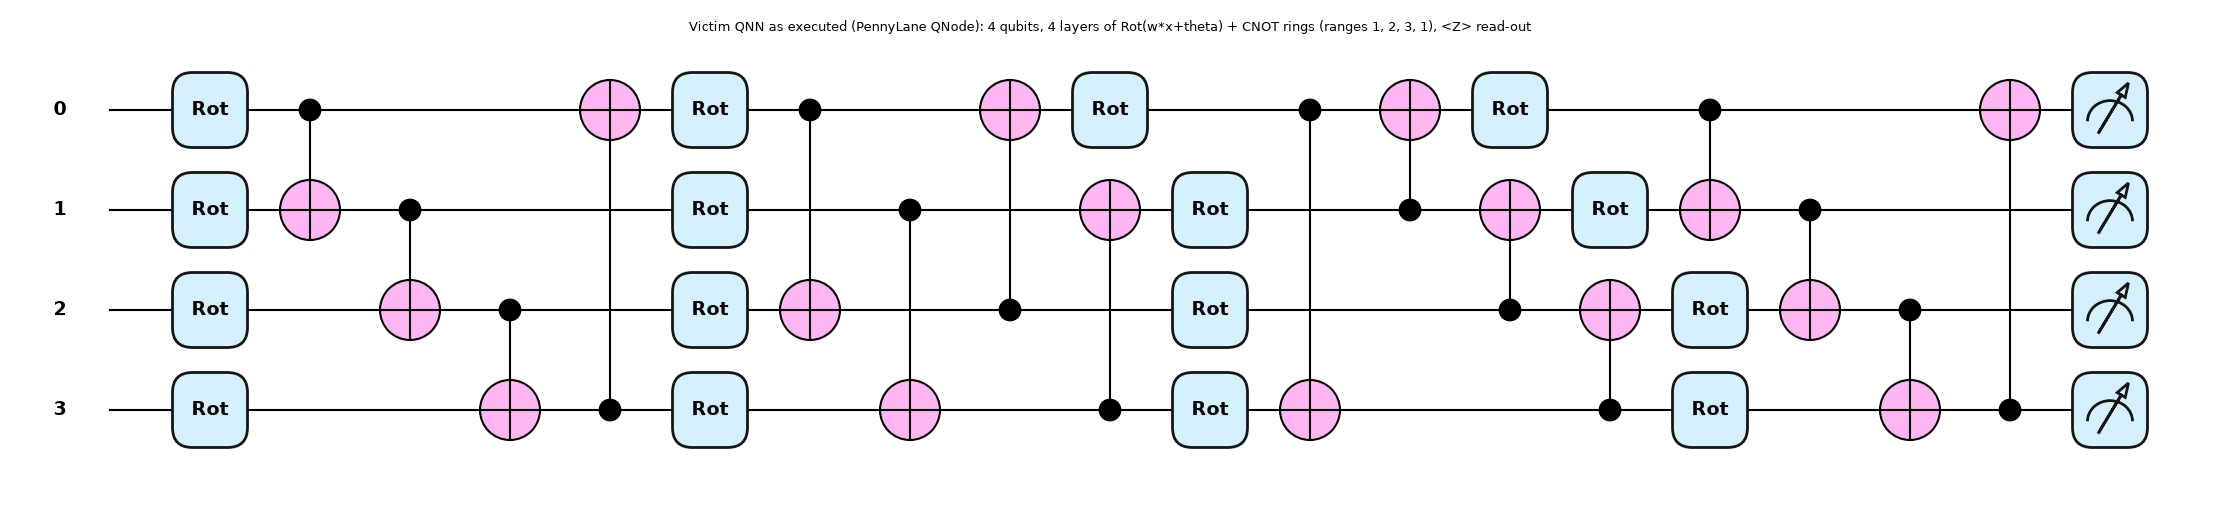

Qiskit logical == AQT-native == PennyLane QNode (expectation values equal)


victim: qubits 4 | PennyLane depth 17 | Qiskit logical depth 25 | native depth 51 | trainable parameters 96 (w: 48, theta: 48)
logical gate counts: {'rz': 32, 'ry': 16, 'cx': 16} | native gate counts: {'r': 80, 'rz': 32, 'rxx': 16}


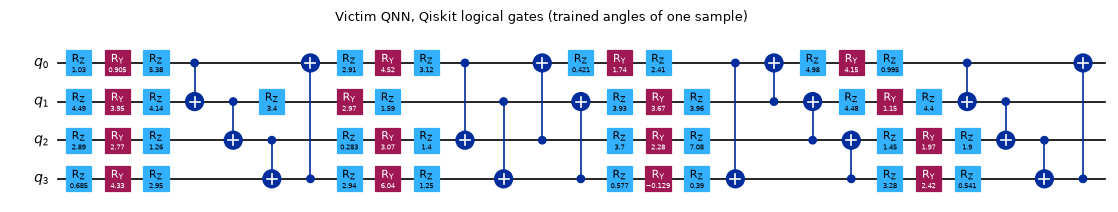

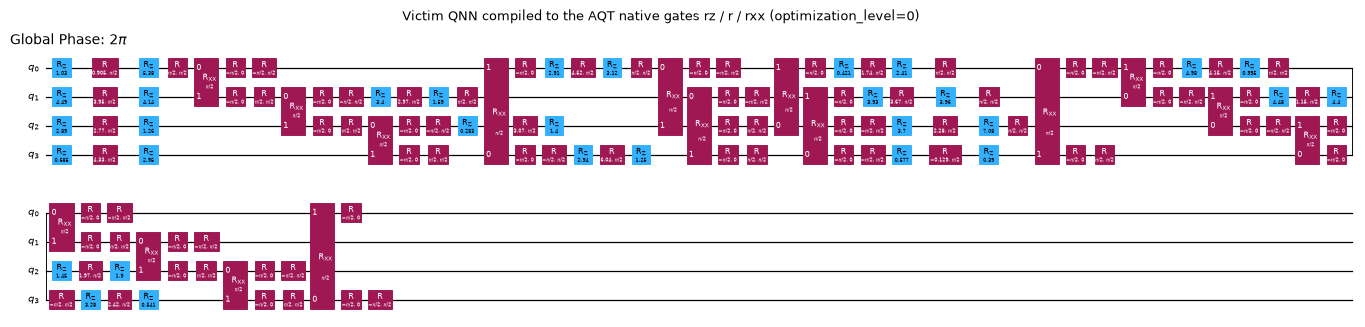

In [18]:
def show_qc(qc, title, **kw):
    fig_ = qc.draw("mpl", **kw); fig_.suptitle(title, fontsize=9); display(fig_); plt.close(fig_)

x_demo = X48[sel[0]]
fig, ax = qml.draw_mpl(victim_qnode, decimals=None, style="pennylane")(x_demo, W_MAIN, TH_MAIN)
fig.suptitle("Victim QNN as executed (PennyLane QNode): 4 qubits, 4 layers of Rot(w*x+theta) + CNOT rings (ranges 1, 2, 3, 1), <Z> read-out", fontsize=9); plt.show()

qc_log = logical_circuit(NQ, L, None, W_MAIN * np.reshape(x_demo, (L, NQ, 3)) + TH_MAIN)
assert np.allclose(z_exp(qc_log, range(NQ)), np.stack(victim_qnode(x_demo, W_MAIN, TH_MAIN)), atol=1e-8)
qc_nat = to_native(qc_log)
assert np.allclose(z_exp(qc_nat, range(NQ)), np.stack(victim_qnode(x_demo, W_MAIN, TH_MAIN)), atol=1e-8)
print("Qiskit logical == AQT-native == PennyLane QNode (expectation values equal)")
try:
    pl_depth = qml.specs(victim_qnode)(x_demo, W_MAIN, TH_MAIN).resources.depth
except Exception:
    pl_depth = "n/a"
print(f"victim: qubits {NQ} | PennyLane depth {pl_depth} | "
      f"Qiskit logical depth {qc_log.depth()} | native depth {qc_nat.depth()} | trainable parameters {2*L*NQ*3} (w: {L*NQ*3}, theta: {L*NQ*3})")
print("logical gate counts:", dict(qc_log.count_ops()), "| native gate counts:", dict(qc_nat.count_ops()))
show_qc(qc_log, "Victim QNN, Qiskit logical gates (trained angles of one sample)", fold=30, scale=0.6)
show_qc(qc_nat, "Victim QNN compiled to the AQT native gates rz / r / rxx (optimization_level=0)", fold=45, scale=0.45)

,qubits,layers,r,depth,cnots,rot_parameters,duration_us
0,4,2,default,12,8,24,2098
1,4,2,1,14,8,24,2098
2,4,2,2,10,8,24,2098
3,4,4,default,25,16,48,4194
4,4,4,1,28,16,48,4194
5,4,4,2,20,16,48,4194
6,4,6,default,37,24,72,6290
7,4,6,1,42,24,72,6290
8,4,6,2,30,24,72,6290
9,4,8,default,48,32,96,8386


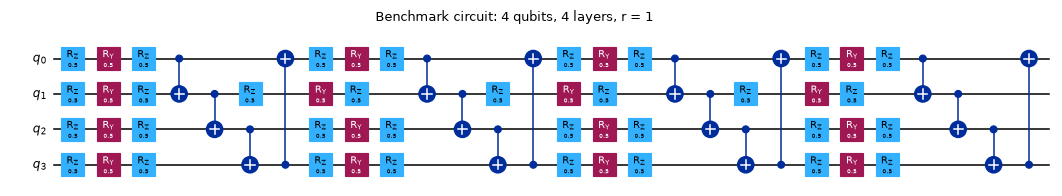

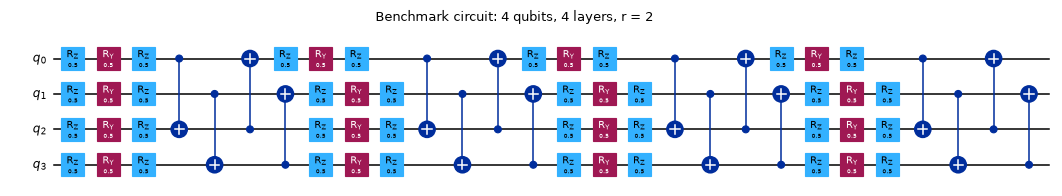

In [19]:
# distinct benchmark architectures used in the power-trace stage (the default-r one is the victim itself)
rows = []
for cfg in BENCH:
    q_ = logical_circuit(cfg[0], cfg[1], cfg[2], np.zeros((cfg[1], cfg[0], 3)))
    rows.append(dict(qubits=cfg[0], layers=cfg[1], r="default" if cfg[2] is None else cfg[2], depth=q_.depth(), cnots=q_.count_ops().get("cx", 0), rot_parameters=3 * cfg[0] * cfg[1], duration_us=bench_T[cfg]))
display(pd.DataFrame(rows))
for r_ in (1, 2):
    qb = logical_circuit(NQ, L, r_, np.zeros((L, NQ, 3)) + 0.5)
    show_qc(qb, f"Benchmark circuit: 4 qubits, 4 layers, r = {r_}", fold=30, scale=0.55)

effective crosstalk circuit executed by Aer (sample 53): qubits 4, depth 60, gates {'r': 80, 'ry': 40, 'rz': 32, 'rxx': 16}
explicit 9-ion circuit (equivalence check): qubits 9, depth 103, gates {'ry': 247, 'r': 80, 'rz': 32, 'rxx': 16}


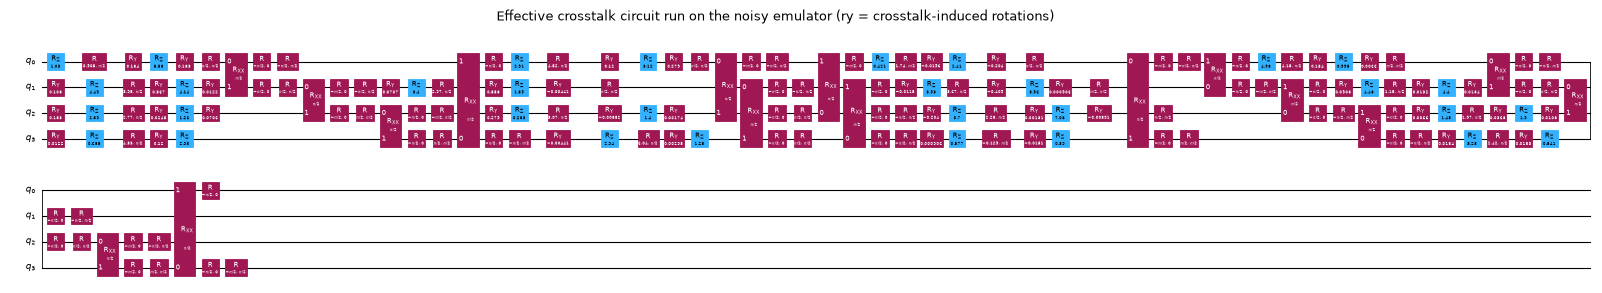

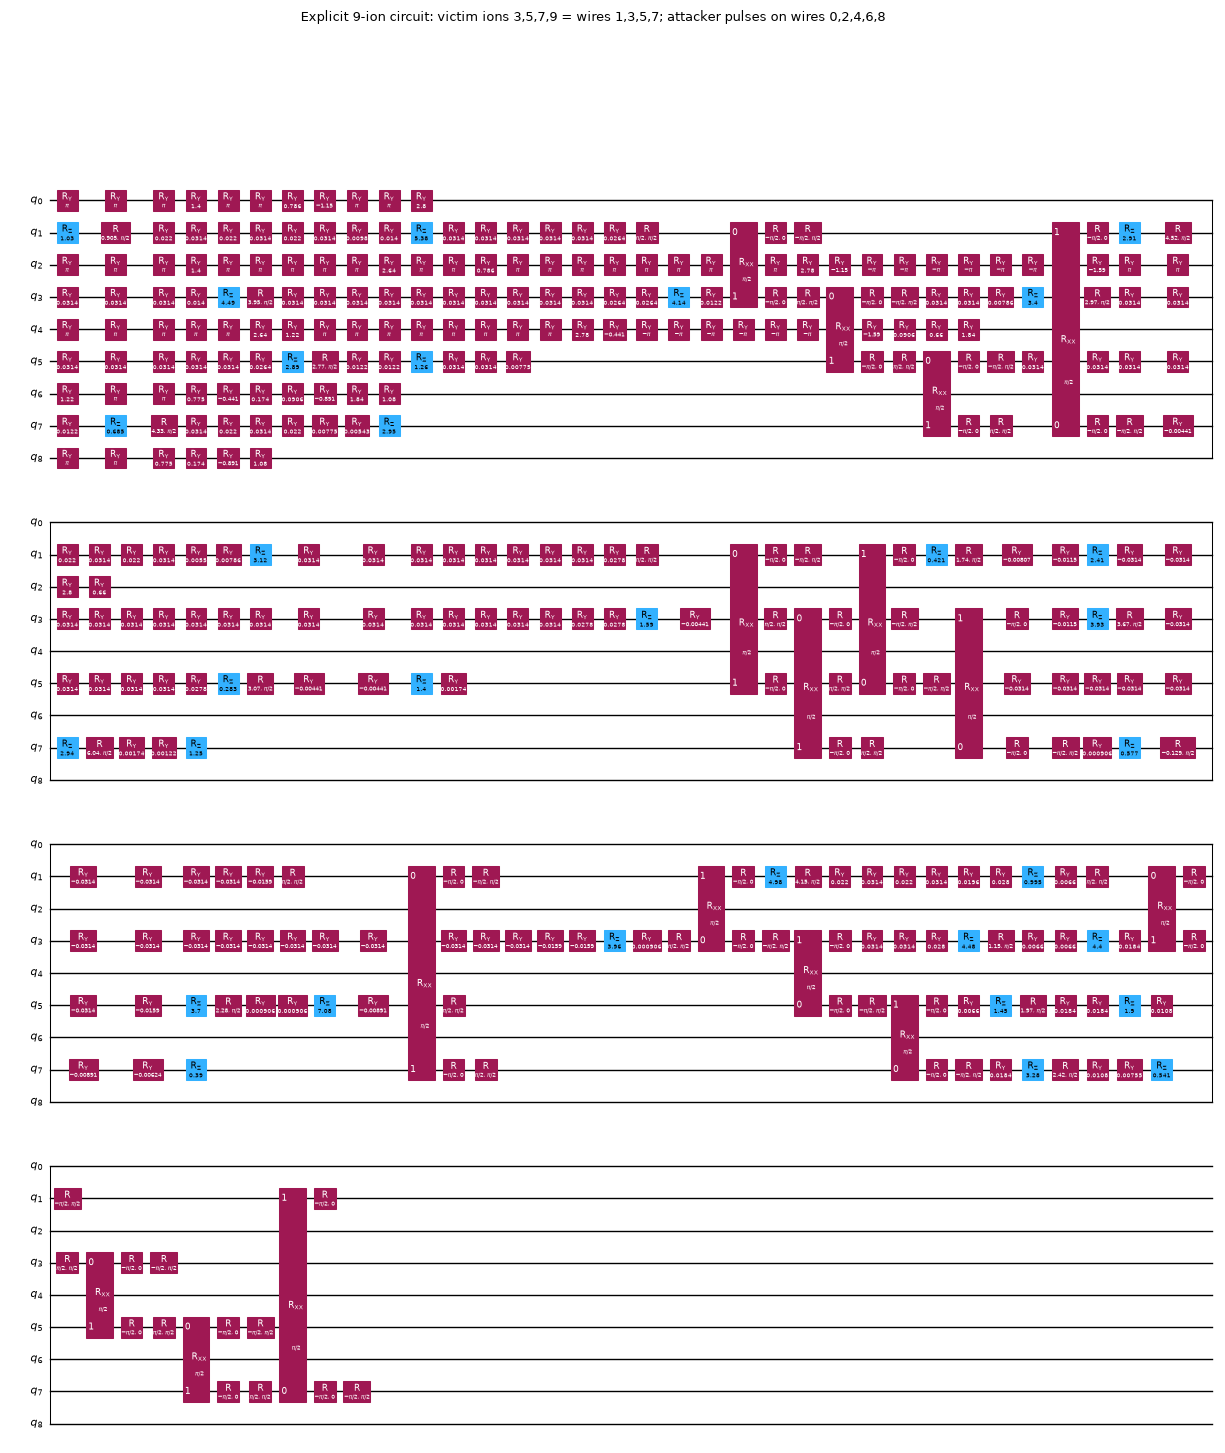

In [20]:
print("effective crosstalk circuit executed by Aer (sample %d): qubits %d, depth %d, gates %s" % (sel[0], qc_x.num_qubits, qc_x.depth(), dict(qc_x.count_ops())))
print("explicit 9-ion circuit (equivalence check): qubits %d, depth %d, gates %s" % (qc_phys.num_qubits, qc_phys.depth(), dict(qc_phys.count_ops())))
show_qc(qc_x, "Effective crosstalk circuit run on the noisy emulator (ry = crosstalk-induced rotations)", fold=60, scale=0.4)
show_qc(qc_phys, "Explicit 9-ion circuit: victim ions 3,5,7,9 = wires 1,3,5,7; attacker pulses on wires 0,2,4,6,8", fold=36, scale=0.5)

## 9. Paper versus this notebook, claim by claim

Verdicts: **reproduced** (within 2 accuracy points / 5 points for rates / 25 % for distances), **not reached** / **exceeded** (with the gap), **cannot be checked** (needs the AQT / IQM hardware or data that the paper does not publish).

In [21]:
def verdict(paper, mine, tol, higher_is_better=None):
    d = mine - paper
    if abs(d) <= tol: return "reproduced"
    if higher_is_better is None: return "not reached (%+.3f)" % d
    return ("exceeded (%+.3f)" if (d > 0) == higher_is_better else "not reached (%+.3f)") % d
tvd = lambda a, b: 0.5 * np.abs(np.asarray(a) / np.sum(a) - np.asarray(b) / np.sum(b)).sum()
tvd6 = tvd(df_t6.samples_paper, df_t6.samples + 1e-9)
rows = [
 ("Victim train accuracy (Sec. IV-B)", 0.885, acc_tr_main, verdict(0.885, acc_tr_main, .02, True)),
 ("Victim test accuracy (Sec. IV-B)", 0.875, acc_te_main, verdict(0.875, acc_te_main, .02, True)),
 ("Stage 1: right circuit identified (fraction of victims)", 1.0, df_pow.correct.mean(), verdict(1.0, df_pow.correct.mean(), 0.0)),
 ("Stage 1: benchmarks left after timing filter", 3, float(df_pow.n_candidates.mean()), "reproduced" if df_pow.n_candidates.mean() == 3 else "not reached (see note: 8q/2 layers has equal duration in our gate count)"),
 ("Stage 1: L2 distance to the right circuit", 9.84, df_pow.d_best.mean(), "reproduced" if abs(df_pow.d_best.mean() / 9.84 - 1) < .25 else "not reached"),
 ("Stage 1: L2 distance to wrong-pattern circuits (r=1 / r=2; paper 119.14 / 132.14)", "119.14 / 132.14", "%.1f / %.1f" % (df_pow.d_r1.mean(), df_pow.d_r2.mean()), "reproduced" if (abs(df_pow.d_r1.mean() / 119.14 - 1) < .25 and abs(df_pow.d_r2.mean() / 132.14 - 1) < .25) else "not reached"),
 ("Table IV row pi/2 recomputed from Table XV counts", "0.007/0.010/0.010/0.010/0.007", "/".join("%.3f" % v for v in df_f["f (recomputed)"]), "reproduced" if f_ok else "not reached"),
 ("Linear crosstalk model vs Table XVII (00000 counts)", "9 published counts", "max dev %d shots" % np.abs(df_t17.published_00000 - df_t17.linear_model).max(), "reproduced" if t17_ok else "not reached"),
 ("Stage 2: PGD success rate on training samples", 0.84, succ2, verdict(0.84, succ2, .05, True)),
 ("Stage 2: accuracy under PGD (paper 1.07 %)", 0.0107, acc_adv2, verdict(0.0107, acc_adv2, .02, False)),
 ("Stage 2: Table VI histogram shape (total variation distance, threshold 0.15)", 0.0, tvd6, "reproduced" if tvd6 <= .15 else "not reached"),
 ("Stage 3: masked PGD success among correct samples", 338 / 885, succ3, verdict(338 / 885, succ3, .05, True)),
 ("Stage 3: masking makes the attack harder (success_masked < success_unmasked)", True, bool(succ3 < succ2), "reproduced" if succ3 < succ2 else "not reached"),
 ("Table VIII hardware accuracy clean / adversarial / crosstalk", "0.64 / 0.56 / 0.68", "emulated: %.2f / %.2f / %.2f" % (acc(hw["clean"]), acc(hw["adv"]), acc(hw["xtalk"])), "cannot be checked (AQT Ibex hardware)"),
 ("Table IX smallest MAE is hw_adv vs hw_crosstalk", "hw_adv vs hw_crosstalk", smallest_pair, "cannot be checked on hardware; emulation: " + ("agrees" if smallest_pair == "hw_adv vs hw_crosstalk" else "differs")),
 ("Appendix A superconducting experiments (power trace on Fake7QPulseV1, Active SWAP on IQM Emerald, Tables X-XIV)", "-", "-", "cannot be checked (pulse backend removed from Qiskit 2.x, IQM hardware)"),
]
df_cmp_all = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90, "display.width", 250); display(df_cmp_all)
print("total run time %.1f min" % ((time.time() - T0) / 60))

,claim,paper,this notebook,verdict
0,Victim train accuracy (Sec. IV-B),0.885,0.883,reproduced
1,Victim test accuracy (Sec. IV-B),0.875,0.87,reproduced
2,Stage 1: right circuit identified (fraction of victims),1.0,1.0,reproduced
3,Stage 1: benchmarks left after timing filter,3,6.0,not reached (see note: 8q/2 layers has equal duration in our gate count)
4,Stage 1: L2 distance to the right circuit,9.84,9.597168,reproduced
5,Stage 1: L2 distance to wrong-pattern circuits (r=1 / r=2; paper 119.14 / 132.14),119.14 / 132.14,117.4 / 121.2,reproduced
6,Table IV row pi/2 recomputed from Table XV counts,0.007/0.010/0.010/0.010/0.007,0.007/0.010/0.010/0.009/0.007,reproduced
7,Linear crosstalk model vs Table XVII (00000 counts),9 published counts,max dev 44 shots,reproduced
8,Stage 2: PGD success rate on training samples,0.84,0.924,exceeded (+0.084)
9,Stage 2: accuracy under PGD (paper 1.07 %),0.0107,0.003,reproduced


total run time 11.0 min


## 10. Reading the paper critically

* **The only hardware numbers are tiny and noisy.** Table VIII rests on 50 samples; one sample is 2 accuracy points and the binomial standard error at accuracy 0.6 is about 7 points, so 0.64 / 0.56 / 0.68 are statistically indistinguishable.
  The "crosstalk" accuracy (0.68) is even higher than the clean one, so the hardware demonstration shows that the attack machinery runs, not that it degrades the classifier. The supporting evidence is the MAE ordering of Table IX (0.1236 vs 0.1270 vs 0.1452), whose differences are also small.
* **The samples were chosen to be favourable to the attacker:** they were picked where the *simulator* is right and masked PGD succeeds, yet the hardware clean accuracy is only 0.64 - these are low-margin samples that the noisy device already misclassifies.
* **Inconsistent baseline numbers.** The model is reported with 0.885 train accuracy in Sec. IV-B but the accuracy "decreases from 92.4 % to 1.07 %" in Sec. V-B. Table VI also contradicts a 1.07 % figure: 791 of the 885 originally correct samples are broken, so at least 94 correct samples (about 9 %) survive every `eps <= 1.0`.
* **The attack budget is huge.** `eps` up to 1.0 is applied in the raw PCA space, whose coordinates range roughly from -3 to 3.6; a typical minimal `eps` of about 0.5 shifts *every* coordinate by up to half a unit, which is a visible change of the image (Fig. 4), not an imperceptible perturbation. The paper does not compare with a classical model of similar size; in this notebook a 172-parameter MLP is broken at least as often and with a smaller `eps`, so the vulnerability is generic, not specific to quantum models.
* **Idealised threat model.** White-box gradients, exact knowledge of the timing of every `RY` gate, a co-located tenant, a clean linear crosstalk model, and a power trace that comes from a *simulator* with the paper's own formulas. The identification step is easy by construction: only the `R` pulse heights differ for the right structure (distance about 10), while a wrong CNOT pattern shifts 200 us `RXX` pulses (distance above 100).
* **Collateral damage.** Because victim qubits sit two ions apart, every attacker pulse next to ion 4 also kicks ion 3 *and* ion 5. The paper mentions this; in the emulated device the collateral rotations are large by construction (the neighbour pulse that is aimed at one ion leaks with the same strength onto the next victim ion, i.e. about half of the intended shift lands on the other qubit) and are one reason why the physical crosstalk image only approximates the adversarial one. The suggested layout `[2,5,8,11]` is a fix on paper only.
* **What we added / cannot do.** The device is emulated with the paper's own linear model, so Stage 3 here is a consistency demonstration, not an independent confirmation. Noise parameters are generic, not AQT calibration data.

## 11. Exercises

1. **Training budget.** Train with Adam, lr 0.001 and 20 epochs (the budget of the 8-qubit predecessor). How do accuracy and the success rate of Table VI change? Is a less-trained QNN more or less robust (the paper cites such an effect)?
2. **Defence by shielding.** Set `F_TRUE` couplings to zero for the pair (4, 5) and (4, 3) (a spacer ion between victim qubits). Re-run the emulation: how large is the accuracy difference between the crosstalk image and the adversarial image?
3. **Better layout.** Place the victim qubits on ions `[2,5,8,11]` as suggested in Sec. VI-A (extend `F_TRUE` to ion 11) and measure how much the collateral error shrinks.
4. **Decoy pulses.** Add random decoy `r` pulses to the victim's power trace (a defence from Sec. VI-B) and find how many are needed before the timing filter and the L2 match fail.
5. **Adversarial training.** Re-train the QNN on PGD examples (`eps = 0.2`) and repeat stages 2 and 3. How many more samples survive masked PGD?